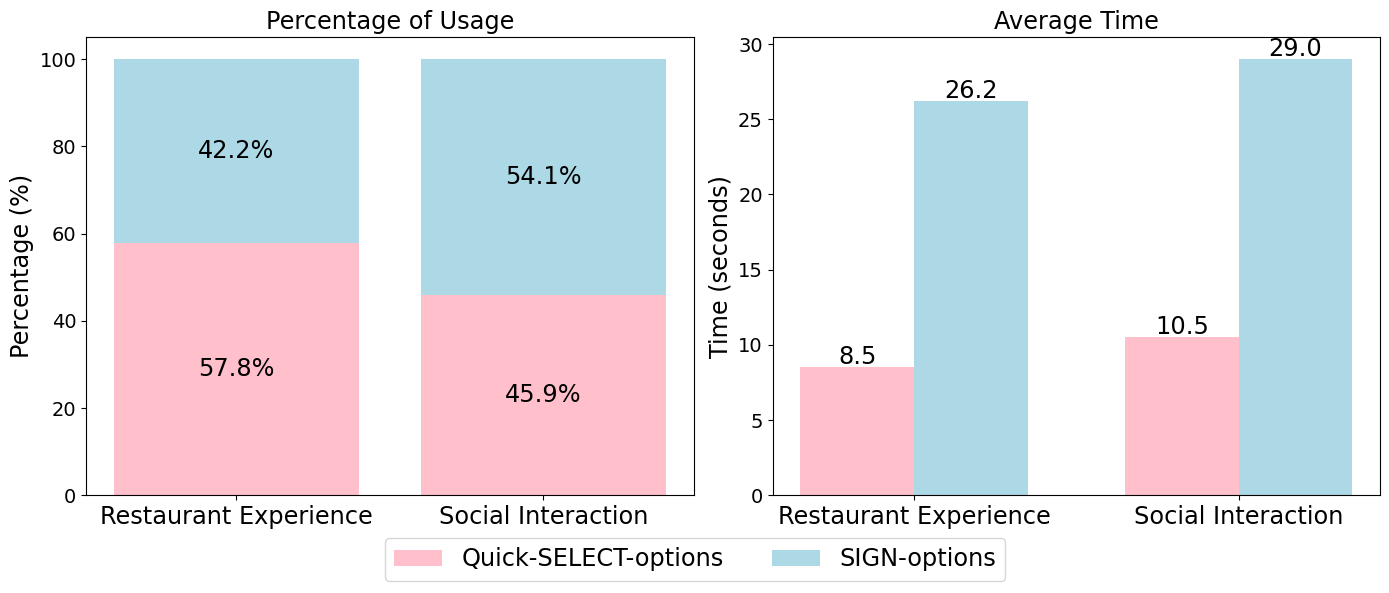

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Data for the first graph (Percentage of using Contextual Options vs Signing)
categories = ['Restaurant Experience', 'Social Interaction']
contextual_options_pct = [57.8, 45.9]
signing_pct = [42.2, 54.1]

# Data for the second graph (Average Time of using Contextual Options vs Signing)
contextual_time = [8.5, 10.5]
signing_time = [26.2, 29.0]

x = np.arange(len(categories))
width = 0.35

# Plotting the stacked bar chart (Percentage)
# Redraw the graphs with only one common legend

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Left plot - Stacked bar chart
bars1 = axs[0].bar(x, contextual_options_pct, label='Select Options', color='pink')
bars2 = axs[0].bar(x, signing_pct, bottom=contextual_options_pct, label='Sign Options', color='lightblue')

for i in range(len(x)):
    axs[0].text(x[i], contextual_options_pct[i] / 2, f"{contextual_options_pct[i]}%", ha='center', va='center', fontsize='xx-large')
    axs[0].text(x[i], contextual_options_pct[i] + signing_pct[i] / 2, f"{signing_pct[i]}%", ha='center', va='center', fontsize='xx-large')

axs[0].set_ylabel('Percentage (%)', fontsize='xx-large')
axs[0].set_title('Percentage of Usage', fontsize='xx-large')
axs[0].tick_params(axis='y', which='major', labelsize=14)
axs[0].tick_params(axis='y', which='minor', labelsize=10)

axs[0].set_xticks(x)
axs[0].set_xticklabels(categories, fontsize='xx-large')


# Right plot - Grouped bar chart
bars3 = axs[1].bar(x - width/2, contextual_time, width, color='pink')
bars4 = axs[1].bar(x + width/2, signing_time, width, color='lightblue')

for i in range(len(x)):
    axs[1].text(x[i] - width/2, contextual_time[i] + 0.2, f"{contextual_time[i]}", ha='center', fontsize='xx-large')
    axs[1].text(x[i] + width/2, signing_time[i] + 0.20, f"{signing_time[i]}", ha='center', fontsize='xx-large')

axs[1].set_ylabel('Time (seconds)', fontsize='xx-large')
axs[1].set_title('Average Time', fontsize='xx-large')
axs[1].set_xticks(x)
axs[1].set_xticklabels(categories,fontsize='xx-large')
axs[1].tick_params(axis='y', which='major', labelsize=14)
axs[1].tick_params(axis='y', which='minor', labelsize=10)

# Common legend from one set of bars
handles = [bars1[0], bars2[0]]
labels = ['Quick-SELECT-options', 'SIGN-options']
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize='xx-large')
plt.tight_layout(rect=[0, 0.085, 1, 1])
plt.savefig("select_options_vs_sign_options.png")
plt.show()


now we make the box plot to compare the typing time, dhh-select-turn, dhh-sign-turn

In [3]:
order_dhh_select_turn_time = {
    5: [10.95300006866455, 8.6489999294281, 9.913000106811523, 11.342000007629395, 10.851999998092651, 10.496999979019165, 6.396000146865845], 
    6 : [9.48799991607666, 8.09000015258789, 8.348000049591064, 7.055999994277954, 6.739000082015991, 9.122999906539917, 9.980999946594238], 
    7:  [8.66599988937378, 6.442999839782715, 10.141999959945679, 10.25, 7.291000127792358, 5.999000072479248],
    8:  [10.351999998092651, 7.813999891281128, 9.38700008392334, 6.822999954223633, 6.135999917984009, 7.852999925613403, 10.871999979019165, 9.168999910354614, 8.103000164031982, 6.825000047683716], 
    9: [6.58299994468689, 6.0299999713897705, 6.758999824523926, 7.521000146865845, 6.447999954223633, 5.860000133514404],
    10:  [6.4649999141693115, 9.434999942779541, 12.500999927520752, 8.116999864578247, 7.414000034332275, 7.79200005531311, 7.480999946594238, 8.22000002861023, 12.347999811172485], 
11:  [10.95300006866455, 8.6489999294281, 9.913000106811523, 11.342000007629395, 10.851999998092651, 10.496999979019165, 6.396000146865845], 

}
order_dhh_sign_turn_time = {
    5:  [23.36299991607666, 32.125, 20.59600019454956, 23.656999826431274, 35.7189998626709, 22.85199999809265],
    6: [32.026999950408936, 14.357999801635742, 19.7739999294281, 25.610000133514404, 25.06500005722046, 52.574000120162964], 
    7:  [20.109999895095825, 18.05400013923645, 29.658999919891357, 23.812000036239624, 22.289000034332275], 
    8:  [22.78500008583069, 33.13000011444092, 28.852999925613403, 35.53499984741211, 21.48800015449524], 
    9: [18.25, 20.378000020980835, 16.924000024795532, 20.401999950408936, 30.29099988937378, 15.714999914169312, 13.956000089645386], 
    10:  [19.088000059127808, 23.621999979019165, 20.662999868392944, 22.22699999809265], 
11:  [23.36299991607666, 32.125, 20.59600019454956, 23.656999826431274, 35.7189998626709, 22.85199999809265],
}





In [4]:
social_dhh_select_turn_time = {
    5: [18.77900004386902, 13.157999992370605, 16.496000051498413], 
    6:  [8.461999893188477, 7.036999940872192, 7.072999954223633], 
    7: [9.042999982833862, 6.710999965667725, 10.26799988746643, 7.724999904632568, 5.453000068664551],
    8: [6.352999925613403, 7.545000076293945, 7.806999921798706, 10.935999870300293, 8.016999959945679, 9.76800012588501, 12.087000131607056, 13.901000022888184, 9.842999935150146, 10.683000087738037, 13.055000066757202, 8.042999982833862], 
    9:  [6.355999946594238, 8.480999946594238, 6.543999910354614, 7.947999954223633, 8.622000217437744, 8.846999883651733, 9.19700002670288, 9.6010000705719, 6.665999889373779, 8.355999946594238, 7.33299994468689, 6.515000104904175, 6.641999959945679, 7.278000116348267, 6.831000089645386], 
    10:  [7.564000129699707, 7.398999929428101, 7.210000038146973, 8.794000148773193, 10.218999862670898, 9.405999898910522, 7.946000099182129, 9.687999963760376, 11.355000019073486, 6.6519999504089355, 10.555999994277954, 11.075000047683716, 10.335999965667725, 12.852999925613403], 
    11:  [18.77900004386902, 13.157999992370605, 16.496000051498413]
}

social_dhh_sign_turn_time = {
    5: [28.55399990081787, 30.865000009536743, 26.69700002670288, 45.18400001525879, 24.270999908447266, 35.00100016593933, 25.966000080108643, 53.830000162124634, 37.23699998855591],
    6: [20.545000076293945, 16.77900004386902, 21.09500002861023, 19.7739999294281, 20.740999937057495, 28.51900005340576, 27.161999940872192, 22.95299983024597, 20.28500008583069, 25.763000011444092, 26.231000185012817, 29.388999938964844, 37.23699998855591, 25.84500002861023], 
    7:  [46.13099980354309, 21.788000106811523, 23.240000009536743, 23.323000192642212, 19.55299997329712, 27.399999856948853, 31.097000122070312, 27.436000108718872, 83.5], 
    8: [21.132999897003174, 28.058000087738037, 28.644999980926514, 20.41000008583069, 26.82100009918213, 25.361000061035156, 22.151000022888184], 
    9:  [15.578999996185303, 46.65599989891052, 15.89299988746643, 17.697999954223633, 20.272000074386597, 17.866999864578247, 18.54100012779236], 
    10:  [23.8510000705719, 14.891000032424927, 18.41200017929077, 28.328999996185303, 15.684000015258789, 45.948999881744385, 22.136000156402588, 18.30899977684021, 21.38599991798401, 27.58299994468689, 17.073999881744385], 
    11:  [28.55399990081787, 30.865000009536743, 26.69700002670288, 45.18400001525879, 24.270999908447266, 35.00100016593933, 25.966000080108643, 53.830000162124634, 37.23699998855591]
    
}


In [77]:
combined_social_select = []
for num, data in social_dhh_select_turn_time.items():
    combined_social_select.extend(data)

combined_order_select = []
for num, data in order_dhh_select_turn_time.items():
    combined_order_select.extend(data)


combined_social_sign = []
for num, data in social_dhh_sign_turn_time.items():
    combined_social_sign.extend(data)

combined_order_sign = []
for num, data in order_dhh_sign_turn_time.items():
    combined_order_sign.extend(data)



In [76]:
data_combined_select

[]

In [6]:
order_typing_dhh_turn_time = {
    5: [40.18599987030029, 27.069000005722046, 6.309999942779541, 2.9819998741149902, 12.674000024795532, 6.927000045776367, 15.793999910354614, 6.601000070571899, 11.750999927520752, 7.92300009727478, 14.658999919891357], 
    6: [20.72100019454956, 11.0, 6.809000015258789, 13.488999843597412, 3.741000175476074, 22.20900011062622, 4.619999885559082, 2.2740001678466797, 21.125, 5.260999917984009, 10.401999950408936, 4.503999948501587, 20.491999864578247, 5.108999967575073, 3.6500000953674316], 
    7: [14.082000017166138, 6.302999973297119, 9.690999984741211, 7.582000017166138, 9.886000156402588, 11.266999959945679, 5.216000080108643, 3.0190000534057617, 16.615000009536743, 7.516000032424927, 10.056999921798706, 5.374000072479248, 9.575000047683716, 18.01699995994568], 
    8: [21.14800000190735, 15.644000053405762, 6.642999887466431, 7.2209999561309814, 13.878999948501587, 15.632999897003174, 11.329999923706055, 21.875, 6.190999984741211, 10.76800012588501, 6.193000078201294, 14.559999942779541, 4.231000185012817], 
    9: [13.823999881744385, 7.0299999713897705, 5.0370001792907715, 7.1549999713897705, 8.478000164031982, 4.1499998569488525, 12.61900019645691, 4.795000076293945, 11.030999898910522, 5.460999965667725, 6.05400013923645], 
    10: [20.384000062942505, 10.601999998092651, 28.447999954223633, 4.127000093460083, 7.009000062942505, 7.944000005722046, 5.450000047683716, 9.186000108718872, 6.510999917984009, 7.349999904632568], 
    11: [15.035000085830688, 6.103000164031982, 16.04200005531311, 9.0239999294281, 12.134999990463257, 4.96399998664856, 24.230000019073486, 8.156999826431274, 16.63700008392334, 13.329999923706055, 7.207000017166138, 6.601999998092651, 8.279000043869019, 12.495000123977661, 33.51600003242493, 7.631999969482422, 9.425999879837036], 
    
    
    

}

social_typing_dhh_turn_time = {
    5: [11.660000085830688, 14.702999830245972, 6.08899998664856, 2.5250000953674316, 12.212000131607056, 35.194000005722046, 9.043999910354614, 2.953000068664551, 16.503999948501587, 18.217000007629395, 2.5999999046325684, 44.95199990272522, 9.145999908447266], 
    6: [21.597000122070312, 23.072999954223633, 27.361000061035156, 21.990000009536743, 15.772000074386597, 9.157000064849854, 5.049000024795532, 6.895999908447266, 9.720999956130981, 8.263000011444092, 3.822000026702881, 7.8420000076293945, 19.94599986076355, 6.704999923706055, 2.9839999675750732, 15.4760000705719, 9.549000024795532, 13.45300006866455, 7.536999940872192, 9.059000015258789, 2.1089999675750732, 5.145999908447266, 3.9509999752044678, 3.5190000534057617, 4.756999969482422, 6.078999996185303], 
    7: [9.275000095367432, 13.470999956130981, 14.652000188827515, 26.508000135421753, 15.996999979019165, 6.480999946594238, 9.933000087738037, 15.509999990463257, 3.867000102996826, 27.384000062942505, 23.768999814987183, 7.95799994468689, 14.053000211715698, 8.684000015258789, 20.496999979019165, 6.251000165939331, 17.631999969482422, 20.663999795913696, 19.64800000190735, 5.496999979019165, 16.520999908447266], 
    8: [6.328000068664551, 8.844000101089478, 14.70799994468689, 15.799000024795532, 6.392999887466431, 13.38100004196167, 12.48199987411499, 18.85800004005432, 8.832000017166138, 12.002000093460083, 63.56899976730347, 2.36899995803833, 6.64900016784668, 16.83299994468689, 8.607999801635742, 4.312999963760376, 9.238999843597412, 3.0409998893737793, 47.144999980926514, 19.6489999294281], 
    9: [6.763000011444092, 13.661999940872192, 11.729999780654907, 7.955999851226807, 4.067999839782715, 28.032000064849854, 11.578999996185303, 12.877000093460083, 9.59500002861023, 6.414000034332275, 3.8329999446868896, 27.111999988555908, 15.085000038146973, 5.995000123977661, 3.6040000915527344, 14.004999876022339, 16.71399998664856, 14.585000038146973, 18.969000101089478, 17.203999996185303], 
    10: [19.16000008583069, 17.210999965667725, 14.638000011444092, 33.212000131607056, 16.598999977111816, 16.97000002861023, 16.643999814987183, 9.633000135421753, 20.78499984741211, 36.2720000743866, 14.946999788284302, 6.5920000076293945, 9.075999975204468, 15.531000137329102, 5.9750001430511475, 23.923999786376953, 20.802000045776367, 2.6610000133514404, 18.14300012588501, 7.265000104904175],
    11: [18.397000074386597, 16.389999866485596, 39.34400010108948, 5.522000074386597, 15.20799994468689, 12.228000164031982, 3.0279998779296875, 18.161999940872192, 23.568000078201294, 32.704999923706055, 13.8989999294281, 48.35199999809265, 9.05299997329712, 15.824999809265137], 

}

In [7]:
combined_social_select = []
for num, data in social_dhh_select_turn_time.items():
    combined_social_select.extend(data)

combined_order_select = []
for num, data in order_dhh_select_turn_time.items():
    combined_order_select.extend(data)


combined_social_sign = []
for num, data in social_dhh_sign_turn_time.items():
    combined_social_sign.extend(data)

combined_order_sign = []
for num, data in order_dhh_sign_turn_time.items():
    combined_order_sign.extend(data)

combined_social_typing = []
for num, data in social_typing_dhh_turn_time.items():
    combined_social_typing.extend(data)

combined_order_typing = []
for num, data in order_typing_dhh_turn_time.items():
    print(data)
    combined_order_typing.extend(data)



[40.18599987030029, 27.069000005722046, 6.309999942779541, 2.9819998741149902, 12.674000024795532, 6.927000045776367, 15.793999910354614, 6.601000070571899, 11.750999927520752, 7.92300009727478, 14.658999919891357]
[20.72100019454956, 11.0, 6.809000015258789, 13.488999843597412, 3.741000175476074, 22.20900011062622, 4.619999885559082, 2.2740001678466797, 21.125, 5.260999917984009, 10.401999950408936, 4.503999948501587, 20.491999864578247, 5.108999967575073, 3.6500000953674316]
[14.082000017166138, 6.302999973297119, 9.690999984741211, 7.582000017166138, 9.886000156402588, 11.266999959945679, 5.216000080108643, 3.0190000534057617, 16.615000009536743, 7.516000032424927, 10.056999921798706, 5.374000072479248, 9.575000047683716, 18.01699995994568]
[21.14800000190735, 15.644000053405762, 6.642999887466431, 7.2209999561309814, 13.878999948501587, 15.632999897003174, 11.329999923706055, 21.875, 6.190999984741211, 10.76800012588501, 6.193000078201294, 14.559999942779541, 4.231000185012817]
[13

In [88]:
combined_order_typing

[40.18599987030029,
 27.069000005722046,
 6.309999942779541,
 2.9819998741149902,
 12.674000024795532,
 6.927000045776367,
 15.793999910354614,
 6.601000070571899,
 11.750999927520752,
 7.92300009727478,
 14.658999919891357,
 20.72100019454956,
 11.0,
 6.809000015258789,
 13.488999843597412,
 3.741000175476074,
 22.20900011062622,
 4.619999885559082,
 2.2740001678466797,
 21.125,
 5.260999917984009,
 10.401999950408936,
 4.503999948501587,
 20.491999864578247,
 5.108999967575073,
 3.6500000953674316,
 14.082000017166138,
 6.302999973297119,
 9.690999984741211,
 7.582000017166138,
 9.886000156402588,
 11.266999959945679,
 5.216000080108643,
 3.0190000534057617,
 16.615000009536743,
 7.516000032424927,
 10.056999921798706,
 5.374000072479248,
 9.575000047683716,
 18.01699995994568,
 21.14800000190735,
 15.644000053405762,
 6.642999887466431,
 7.2209999561309814,
 13.878999948501587,
 15.632999897003174,
 11.329999923706055,
 21.875,
 6.190999984741211,
 10.76800012588501,
 6.193000078201

In [91]:
def print_data(data):
    q75, q25 = np.percentile(data, [75 ,25])
    iqr = q75 - q25
    print("Median is ",np.median(data))
    print("Quartile 75%: ", q75)
    print("Quartile 25%: " ,q25)
    print("IQR", iqr)
print("Select options restaurant", )
print_data(combined_order_select)
print()

print("Select options social", )
print_data(combined_social_select)
print()


print("Sign options restaurant", )
print_data(combined_order_sign)
print()


print("Sign options social", )
print_data(combined_social_sign)
print()


print("phone based typing restaurant")
print_data(combined_order_typing)
print()



print("phone based typing social")
print_data(combined_social_typing)
print()



Select options restaurant
Median is  8.284000039100647
Quartile 75%:  10.168999969959259
Quartile 25%:  6.824500024318695
IQR 3.344499945640564

Select options social
Median is  8.622000217437744
Quartile 75%:  10.619500041007996
Quartile 25%:  7.305500030517578
IQR 3.3140000104904175

Sign options restaurant
Median is  22.85199999809265
Quartile 75%:  29.25599992275238
Quartile 25%:  20.389999985694885
IQR 8.865999937057495

Sign options social
Median is  25.905500054359436
Quartile 75%:  29.20299994945526
Quartile 25%:  20.594000041484833
IQR 8.608999907970428

phone based typing restaurant
Median is  9.0239999294281
Quartile 75%:  13.980499982833862
Quartile 25%:  6.2480000257492065
IQR 7.732499957084656

phone based typing social
Median is  13.129000067710876
Quartile 75%:  18.015250086784363
Quartile 25%:  6.719499945640564
IQR 11.295750141143799



In [70]:
all_dhh_select = []
for key, value in order_dhh_select_turn_time.items():
    all_dhh_select.extend(value)
for key, value in social_dhh_select_turn_time.items():
    all_dhh_select.extend(value)

all_dhh_sign = []
for key, value in order_dhh_sign_turn_time.items():
    all_dhh_sign.extend(value)
for key, value in social_dhh_sign_turn_time.items():
    all_dhh_sign.extend(value)

all_typing = []
for key, value in order_typing_dhh_turn_time.items():
    all_typing.extend(value)
for key, value in social_typing_dhh_turn_time.items():
    all_typing.extend(value)

In [71]:
print("mean dhh-select time", np.mean(all_dhh_select))
print("std dhh-select time", np.std(all_dhh_select))
print("mean dhh-sign time", np.mean(all_dhh_sign))
print("std dhh-sign time", np.std(all_dhh_sign))
print("mean typing time", np.mean(all_typing))
print("std typing time", np.std(all_typing))


mean dhh-select time 9.066112146199307
std dhh-select time 2.5694504724173948
mean dhh-sign time 26.694742858977545
std dhh-sign time 10.191822461231668
mean typing time 12.927404443952772
std typing time 9.11141058230902


In [72]:
from matplotlib.patches import Patch


NameError: name 'positions_select' is not defined

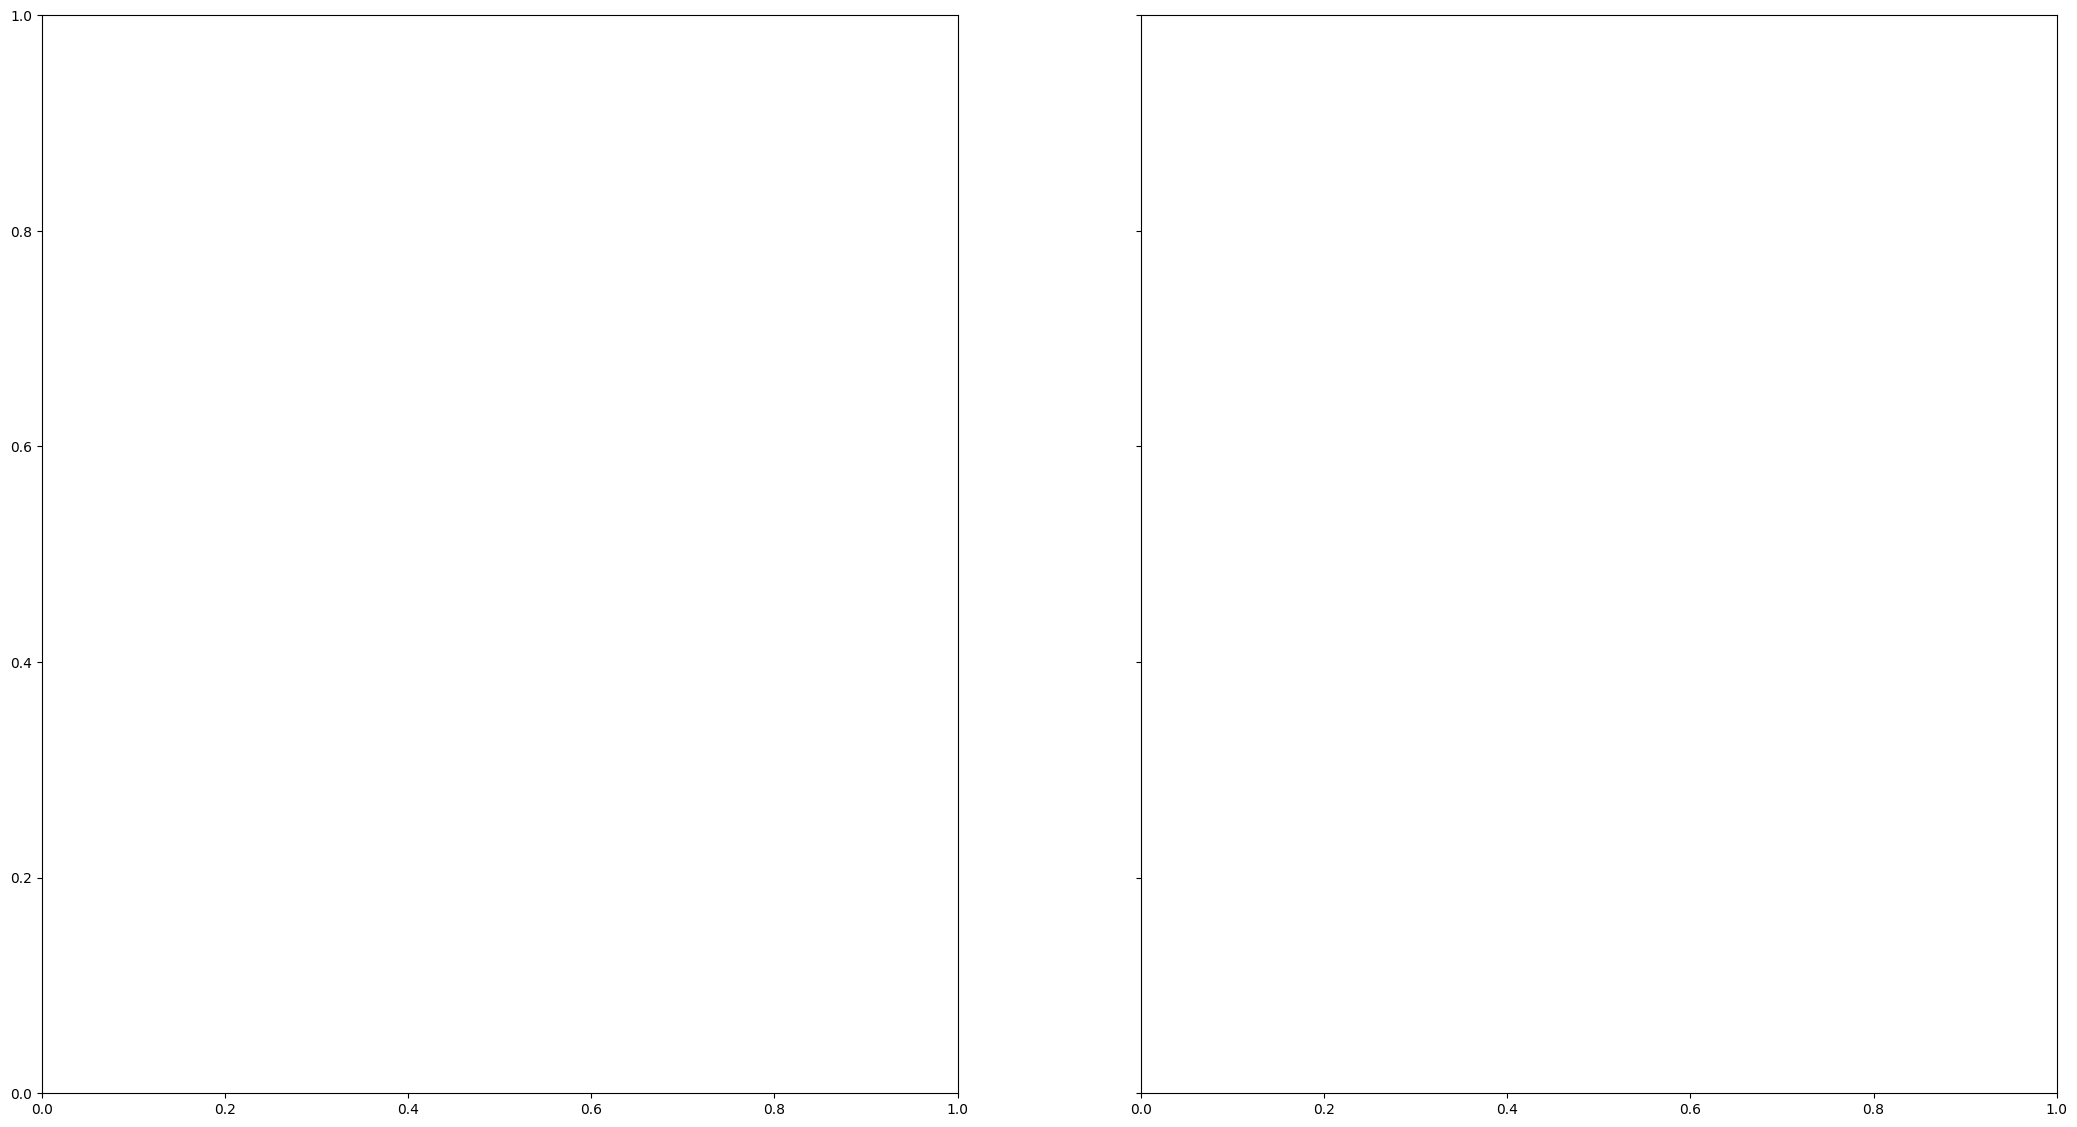

In [73]:
# Replot with even larger text for improved readability
fig, axs = plt.subplots(1, 2, figsize=(26, 14), sharey=True)

# Bigger font sizes
title_fontsize = 26
label_fontsize = 22
tick_fontsize = 20
legend_fontsize = 20
box_width = 0.6

# Order Scenario
bp_order_select = axs[0].boxplot(data_order_select, positions=positions_select, widths=box_width, patch_artist=True, manage_ticks=False)
bp_order_sign = axs[0].boxplot(data_order_sign, positions=positions_sign, widths=box_width, patch_artist=True, manage_ticks=False)
bp_order_typing = axs[0].boxplot(data_order_typing, positions=positions_typing, widths=box_width, patch_artist=True, manage_ticks=False)

for box in bp_order_select['boxes']:
    box.set_facecolor('lightblue')
for box in bp_order_sign['boxes']:
    box.set_facecolor('lightgreen')
for box in bp_order_typing['boxes']:
    box.set_facecolor('lightcoral')

axs[0].set_title('Order Scenario', fontsize=title_fontsize)
axs[0].set_xticks(x_spaced)
axs[0].set_xticklabels(participants, fontsize=tick_fontsize)
axs[0].set_xlabel('Participant', fontsize=label_fontsize)
axs[0].set_ylabel('Time (seconds)', fontsize=label_fontsize)

# Social Scenario
bp_social_select = axs[1].boxplot(data_social_select, positions=positions_select, widths=box_width, patch_artist=True, manage_ticks=False)
bp_social_sign = axs[1].boxplot(data_social_sign, positions=positions_sign, widths=box_width, patch_artist=True, manage_ticks=False)
bp_social_typing = axs[1].boxplot(data_social_typing, positions=positions_typing, widths=box_width, patch_artist=True, manage_ticks=False)

for box in bp_social_select['boxes']:
    box.set_facecolor('lightblue')
for box in bp_social_sign['boxes']:
    box.set_facecolor('lightgreen')
for box in bp_social_typing['boxes']:
    box.set_facecolor('lightcoral')

axs[1].set_title('Social Scenario', fontsize=title_fontsize)
axs[1].set_xticks(x_spaced)
axs[1].set_xticklabels(participants, fontsize=tick_fontsize)
axs[1].set_xlabel('Participant', fontsize=label_fontsize)

# Legend
legend_elements = [
    Patch(facecolor='lightblue', edgecolor='black', label='dhh-select-turn'),
    Patch(facecolor='lightgreen', edgecolor='black', label='dhh-sign-turn'),
    Patch(facecolor='lightcoral', edgecolor='black', label='typing')
]
fig.legend(handles=legend_elements, loc='upper center', ncol=3, fontsize=legend_fontsize)

plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()


In [8]:
# Combine data from all participants for each input method in both scenarios

# Order scenario
combined_order_select = sum(data_order_select, [])
combined_order_sign = sum(data_order_sign, [])
combined_order_typing = sum(data_order_typing, [])

# Social scenario
combined_social_select = sum(data_social_select, [])
combined_social_sign = sum(data_social_sign, [])
combined_social_typing = sum(data_social_typing, [])

# Combine into scenario-based datasets
order_data = [combined_order_select, combined_order_sign, combined_order_typing]
social_data = [combined_social_select, combined_social_sign, combined_social_typing]

labels = ['dhh-select-turn', 'dhh-sign-turn', 'typing']
colors = ['lightblue', 'lightgreen', 'lightcoral']

fig, axs = plt.subplots(1, 2, figsize=(20, 12), sharey=True)

# Font sizes
title_fontsize = 26
label_fontsize = 22
tick_fontsize = 20
legend_fontsize = 20

# Order Scenario
bp_order = axs[0].boxplot(order_data, patch_artist=True, widths=0.6)
for patch, color in zip(bp_order['boxes'], colors):
    patch.set_facecolor(color)

axs[0].set_title('Order Scenario', fontsize=title_fontsize)
axs[0].set_xticks([1, 2, 3])
axs[0].set_xticklabels(labels, fontsize=tick_fontsize)
axs[0].set_xlabel('Input Method', fontsize=label_fontsize)
axs[0].set_ylabel('Time (seconds)', fontsize=label_fontsize)

# Social Scenario
bp_social = axs[1].boxplot(social_data, patch_artist=True, widths=0.6)
for patch, color in zip(bp_social['boxes'], colors):
    patch.set_facecolor(color)

axs[1].set_title('Social Scenario', fontsize=title_fontsize)
axs[1].set_xticks([1, 2, 3])
axs[1].set_xticklabels(labels, fontsize=tick_fontsize)
axs[1].set_xlabel('Input Method', fontsize=label_fontsize)

plt.tight_layout()
plt.show()


NameError: name 'data_order_select' is not defined

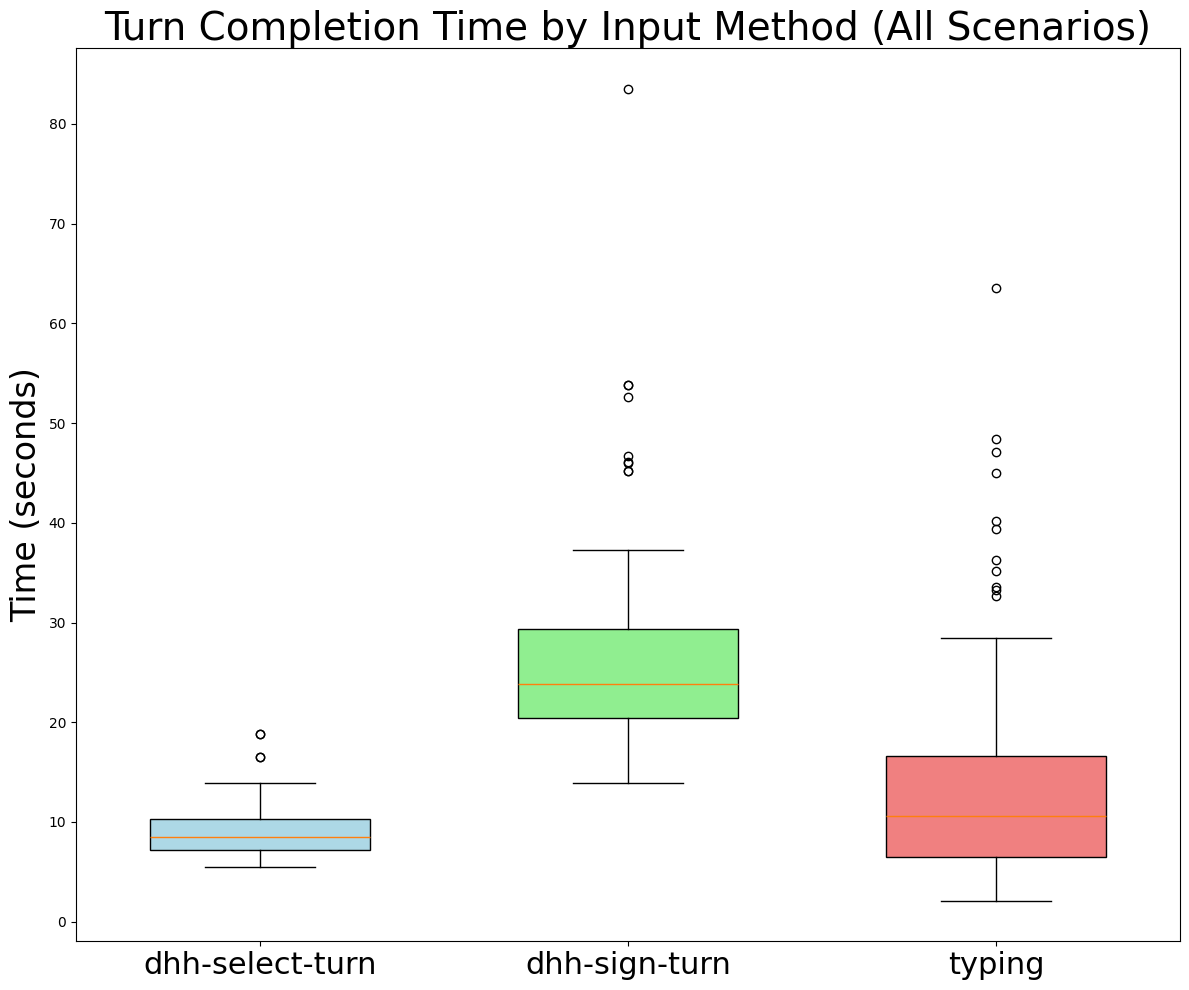

In [9]:
# Combine all data from both scenarios into a single set per input method
all_select = combined_order_select + combined_social_select
all_sign = combined_order_sign + combined_social_sign
all_typing = combined_order_typing + combined_social_typing

combined_data = [all_select, all_sign, all_typing]
labels = ['dhh-select-turn', 'dhh-sign-turn', 'typing']
colors = ['lightblue', 'lightgreen', 'lightcoral']

# Create a single box plot
fig, ax = plt.subplots(figsize=(12, 10))

# Font sizes
title_fontsize = 28
label_fontsize = 24
tick_fontsize = 22

bp = ax.boxplot(combined_data, patch_artist=True, widths=0.6)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Turn Completion Time by Input Method (All Scenarios)', fontsize=title_fontsize)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(labels, fontsize=tick_fontsize)
ax.set_ylabel('Time (seconds)', fontsize=label_fontsize)

plt.tight_layout()
plt.show()


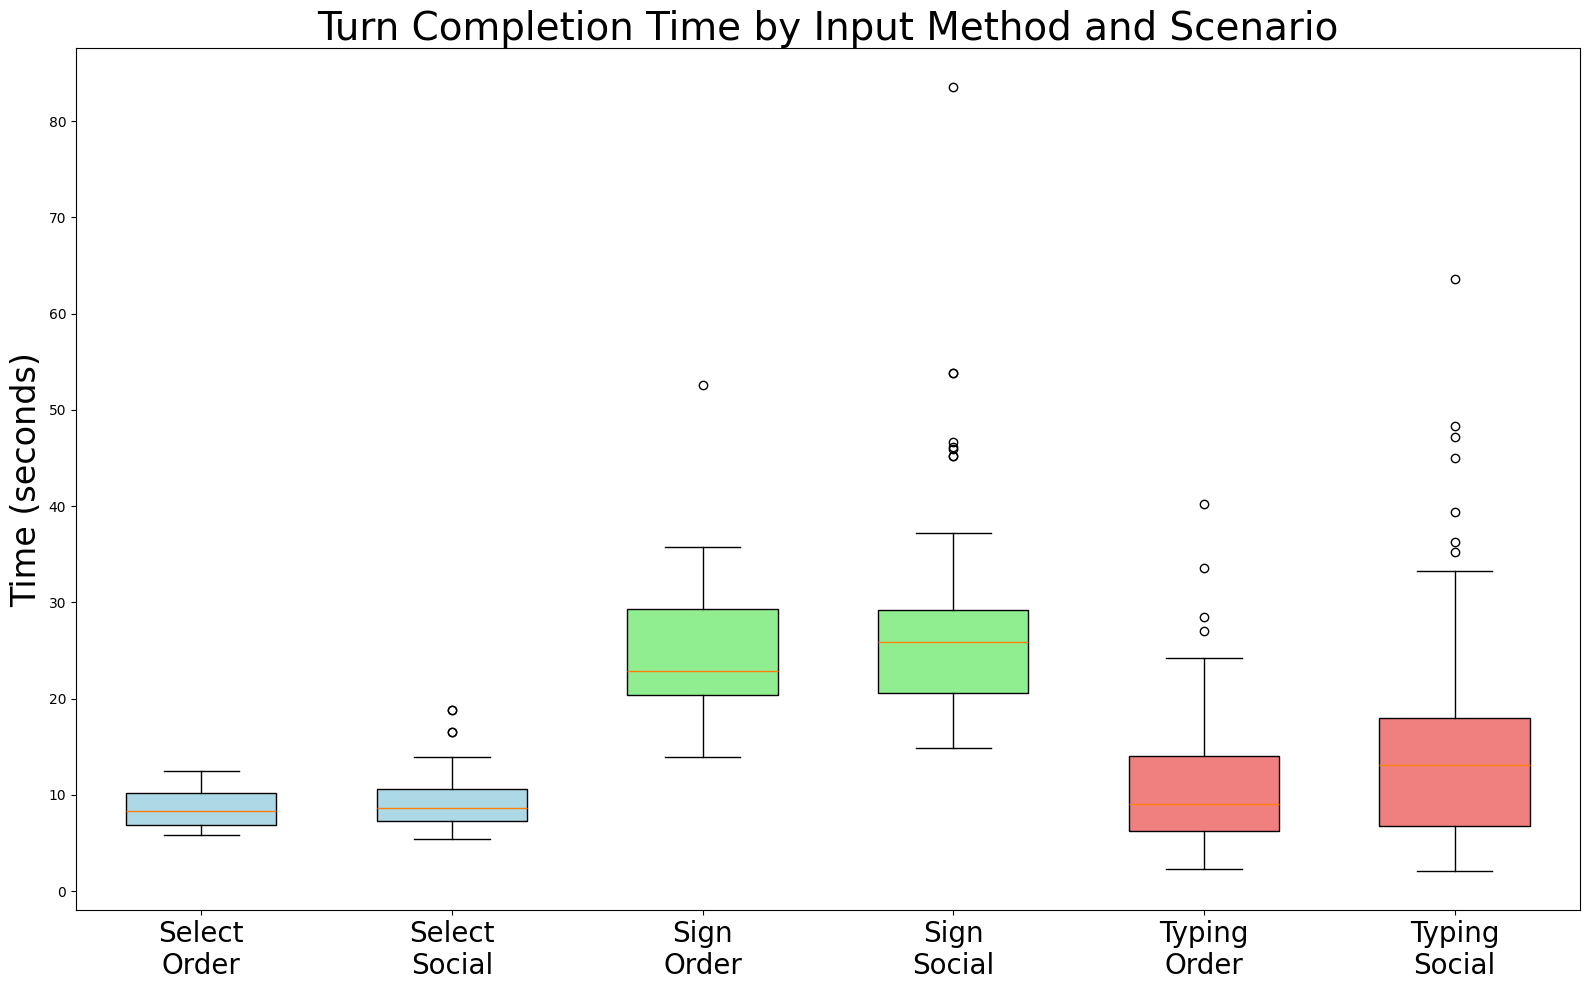

In [10]:
# Organize data by scenario and method for side-by-side comparison
grouped_data = [
    combined_order_select, combined_social_select,
    combined_order_sign, combined_social_sign,
    combined_order_typing, combined_social_typing
]

group_labels = ['Order', 'Social'] * 3
method_labels = ['dhh-select-turn'] * 2 + ['dhh-sign-turn'] * 2 + ['typing'] * 2
x_labels = ['Select\nOrder', 'Select\nSocial', 'Sign\nOrder', 'Sign\nSocial', 'Typing\nOrder', 'Typing\nSocial']
colors = ['lightblue', 'lightblue', 'lightgreen', 'lightgreen', 'lightcoral', 'lightcoral']

# Create the plot
fig, ax = plt.subplots(figsize=(16, 10))

# Font sizes
title_fontsize = 28
label_fontsize = 24
tick_fontsize = 20

bp = ax.boxplot(grouped_data, patch_artist=True, widths=0.6)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Turn Completion Time by Input Method and Scenario', fontsize=title_fontsize)
ax.set_xticks(range(1, 7))
ax.set_xticklabels(x_labels, fontsize=tick_fontsize)
ax.set_ylabel('Time (seconds)', fontsize=label_fontsize)

plt.tight_layout()
plt.show()


In [11]:
# Define colorblind-friendly palette using distinct, high-contrast colors
colors = [
    '#E69F00', '#F0E442',  # orange and yellow for dhh-select-turn (Order, Social)
    '#56B4E9', '#0072B2',  # light blue and dark blue for dhh-sign-turn (Order, Social)
    '#009E73', '#D55E00'   # green and reddish-orange for typing (Order, Social)
]

# Update legend to match new color scheme
legend_elements = [
    Patch(facecolor='#E69F00', label='Select - Order'),
    Patch(facecolor='#F0E442', label='Select - Social'),
    Patch(facecolor='#56B4E9', label='Sign - Order'),
    Patch(facecolor='#0072B2', label='Sign - Social'),
    Patch(facecolor='#009E73', label='Typing - Order'),
    Patch(facecolor='#D55E00', label='Typing - Social')
]

# Re-plot with colorblind-friendly palette
fig, ax = plt.subplots(figsize=(16, 10))

# Font sizes
title_fontsize = 28
label_fontsize = 24
tick_fontsize = 20

bp = ax.boxplot(grouped_data, positions=positions, patch_artist=True, widths=0.25)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Turn Completion Time by Input Method and Scenario', fontsize=title_fontsize)
ax.set_xticks([1.125, 2.125, 3.125])
ax.set_xticklabels(['dhh-select-turn', 'dhh-sign-turn', 'typing'], fontsize=tick_fontsize)
ax.set_ylabel('Time (seconds)', fontsize=label_fontsize)

ax.legend(handles=legend_elements, title="Input Method & Scenario", loc='upper right', fontsize=tick_fontsize, title_fontsize=label_fontsize)

plt.tight_layout()
plt.show()


NameError: name 'Patch' is not defined

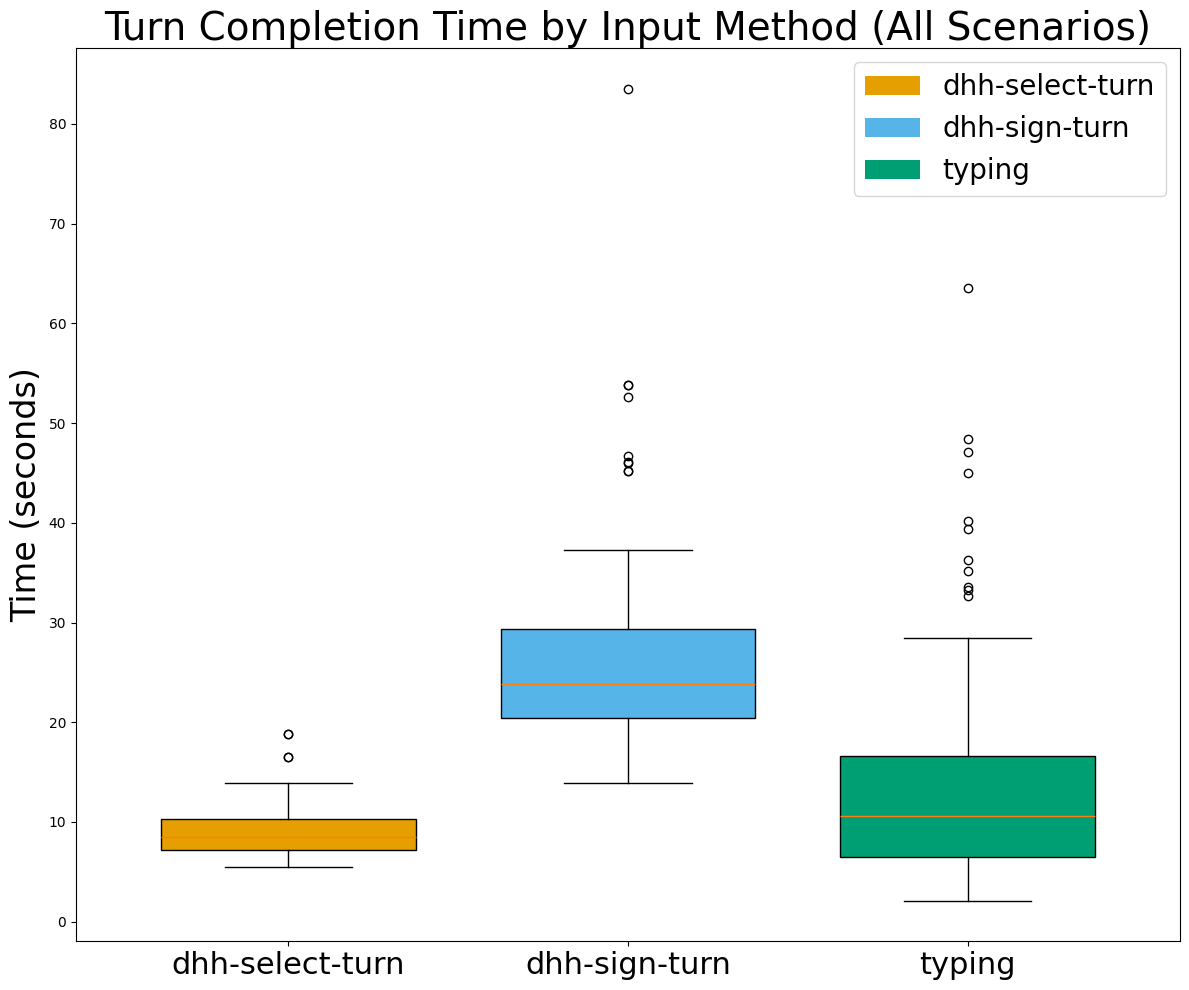

In [12]:
from matplotlib.patches import Patch
import matplotlib.pyplot as plt

# Create the plot with legend added
fig, ax = plt.subplots(figsize=(12, 10))

# Font sizes
title_fontsize = 28
label_fontsize = 24
tick_fontsize = 22
legend_fontsize = 20

# Colorblind-friendly colors
cbf_colors = ['#E69F00', '#56B4E9', '#009E73']
labels = ['dhh-select-turn', 'dhh-sign-turn', 'typing']
combined_data = [all_select, all_sign, all_typing]

# Define custom positions for the boxplots to reduce whitespace. 
# Adjust the positions to be closer than the default [1, 2, 3] while ensuring boxes do not intersect.
positions = [1, 1.8, 2.6]  # Example positions with reduced spacing

# Create the boxplot with custom positions
bp = ax.boxplot(combined_data, patch_artist=True, widths=0.6, positions=positions)
for patch, color in zip(bp['boxes'], cbf_colors):
    patch.set_facecolor(color)

ax.set_title('Turn Completion Time by Input Method (All Scenarios)', fontsize=title_fontsize)
ax.set_xticks(positions)
ax.set_xticklabels(labels, fontsize=tick_fontsize)
ax.set_ylabel('Time (seconds)', fontsize=label_fontsize)

# Add legend
legend_elements = [Patch(facecolor=cbf_colors[i], label=labels[i]) for i in range(3)]
ax.legend(handles=legend_elements, loc='upper right', fontsize=legend_fontsize)

plt.tight_layout()
plt.show()


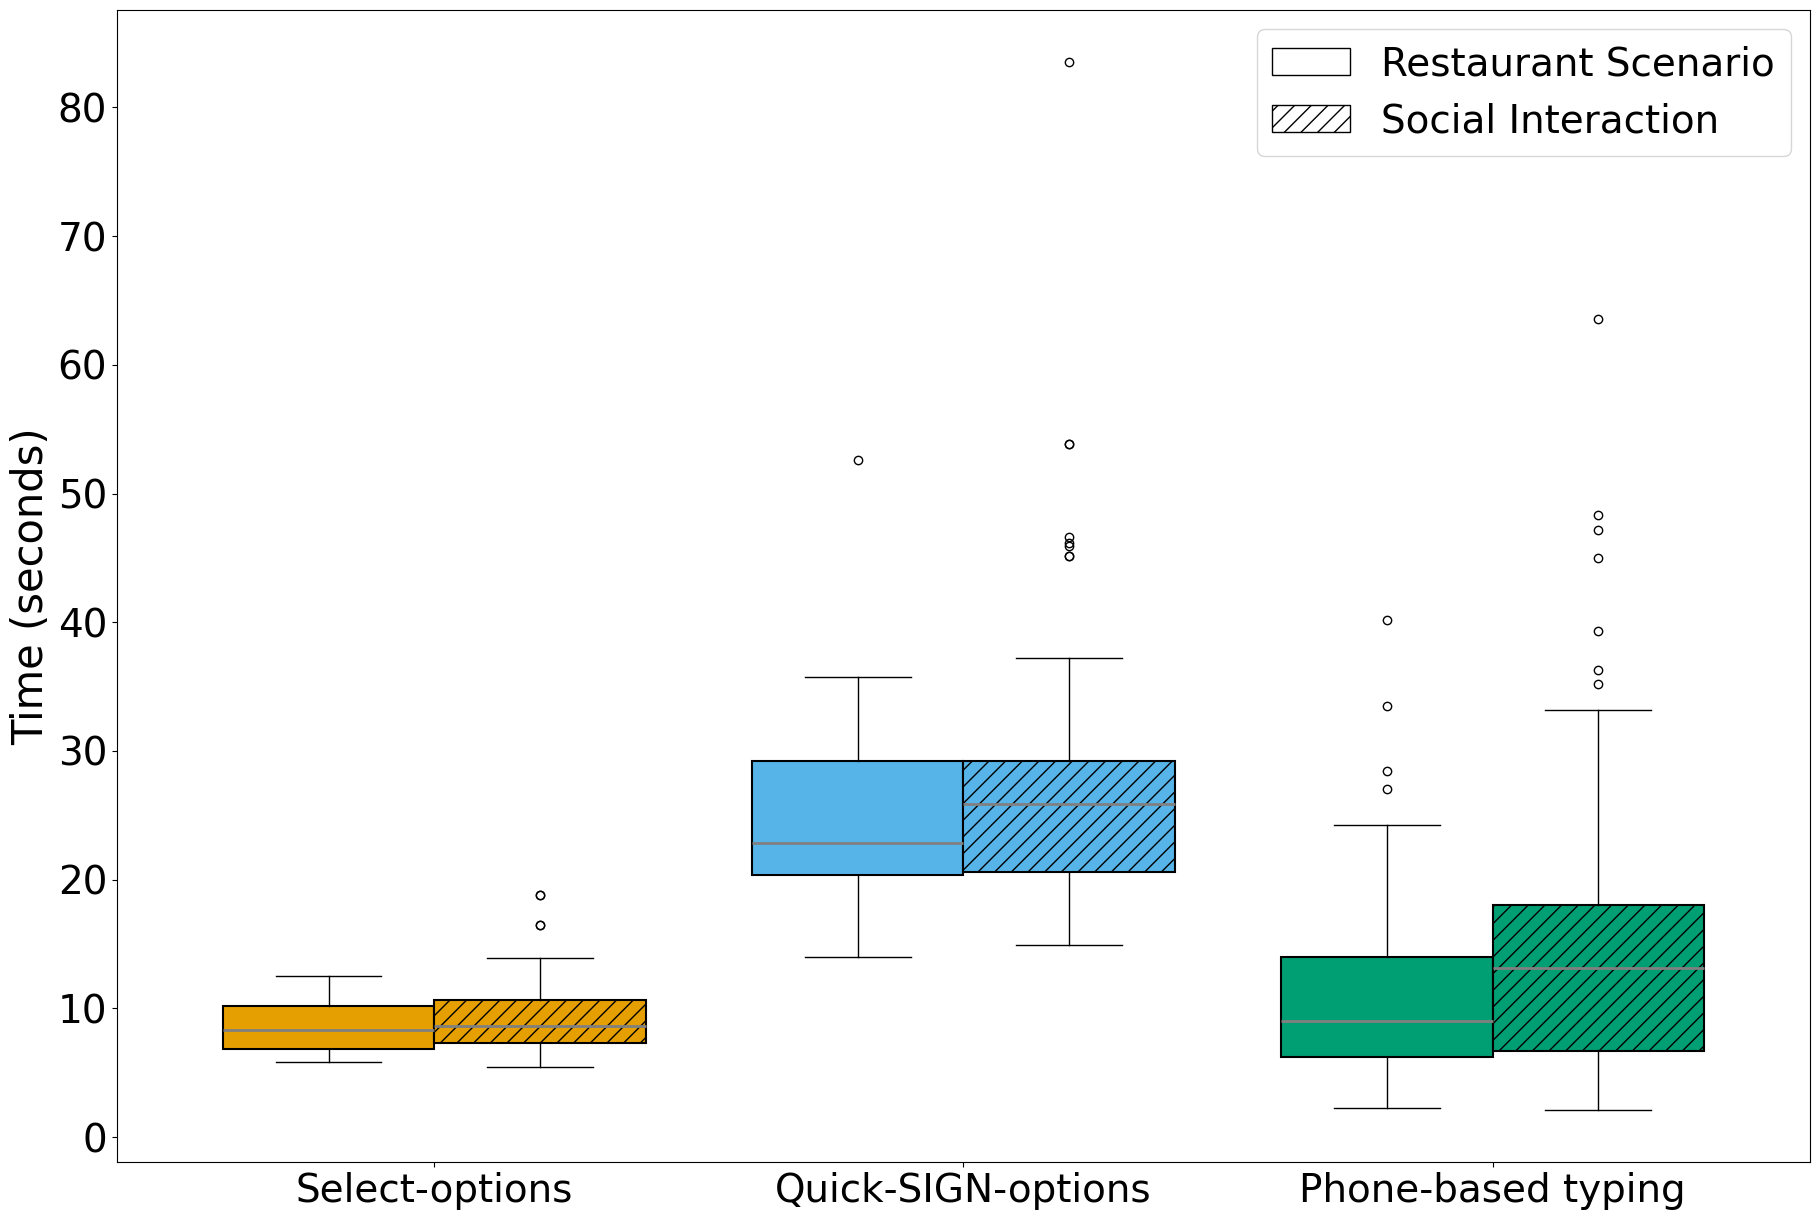

[[10.95300006866455,
  8.6489999294281,
  9.913000106811523,
  11.342000007629395,
  10.851999998092651,
  10.496999979019165,
  6.396000146865845,
  9.48799991607666,
  8.09000015258789,
  8.348000049591064,
  7.055999994277954,
  6.739000082015991,
  9.122999906539917,
  9.980999946594238,
  8.66599988937378,
  6.442999839782715,
  10.141999959945679,
  10.25,
  7.291000127792358,
  5.999000072479248,
  10.351999998092651,
  7.813999891281128,
  9.38700008392334,
  6.822999954223633,
  6.135999917984009,
  7.852999925613403,
  10.871999979019165,
  9.168999910354614,
  8.103000164031982,
  6.825000047683716,
  6.58299994468689,
  6.0299999713897705,
  6.758999824523926,
  7.521000146865845,
  6.447999954223633,
  5.860000133514404,
  6.4649999141693115,
  9.434999942779541,
  12.500999927520752,
  8.116999864578247,
  7.414000034332275,
  7.79200005531311,
  7.480999946594238,
  8.22000002861023,
  12.347999811172485,
  10.95300006866455,
  8.6489999294281,
  9.913000106811523,
  11.

In [18]:
# Adjust x-axis limits to remove inner whitespace at the start and end of the figure
fig, ax = plt.subplots(figsize=(18, 12))
positions = [1, 1.25, 1.625, 1.875, 2.25, 2.5]
uniform_colors = [
    '#E69F00', '#E69F00',  # Select-options (same color for both scenarios)
    '#56B4E9', '#56B4E9',  # Sign-options
    '#009E73', '#009E73'   # Phone-based typing
]
social_indices = [1, 3, 5]

# Font sizes
title_fontsize = 34
label_fontsize = 30
tick_fontsize = 28

bp = ax.boxplot(grouped_data, positions=positions, patch_artist=True, widths=0.25)

for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(uniform_colors[i])
    patch.set_linewidth(1.5)
    patch.set_edgecolor('black')
    if i in social_indices:
        patch.set_hatch('//')

# Adjust x-axis limits tightly around the data
ax.set_xlim(min(positions) - 0.25, max(positions) + 0.25)

ax.set_xticks([1.125, 1.75, 2.375])
ax.set_xticklabels(['Select-options', 'Quick-SIGN-options', 'Phone-based typing'], fontsize=tick_fontsize)
ax.set_ylabel('Time (seconds)', fontsize=label_fontsize)
ax.tick_params(axis='y', labelsize=tick_fontsize)

# Legend
legend_elements = [
    Patch(facecolor='white', edgecolor='black', label='Restaurant Scenario'),
    Patch(facecolor='white', edgecolor='black', hatch='//', label='Social Interaction')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=tick_fontsize, title_fontsize=label_fontsize)
for median in bp['medians']:
    median.set_color('gray')
    median.set_linewidth(2)           # Thicker line
# Save with tight bounding box and no padding
plt.savefig("turn_completion_time_scenarios.png", dpi=300, bbox_inches='tight', pad_inches=0)
plt.tight_layout(pad=0)
plt.show()
grouped_data

# Now, we do the SUS user survey q1-10

In [8]:
import textwrap


sus_questions = {
1: "I think that I would like to use this system frequently when communicating with hearing individuals",
2: "I found the system unnecessarily complex",
3: "I thought the system was easy to use",
4: "I think that I would need the support of a technical person to be able to use this system",
5: "I found the various functions in this system were well integrated",
6: "I thought there was too much inconsistency in this system", 
7: "I would imagine that DHH individuals would learn to use this system very quickly", 
8: "I found the system very cumbersome to use", 
9: "I felt very confident using the system", 
10: "I needed to learn a lot of things before I could get going with this system be able to use this system", 
    
}

categories = ["Strongly Disagree", "Disagree", "Neutral", "Agree", "Strongly Agree"]



sus_questions_with_newline = dict()

for number, question in sus_questions.items(): 
    sus_questions_with_newline[number] = '\n'.join(textwrap.wrap(question, 55))


sus_answers_category_count = {
    sus_questions_with_newline[1]: [0, 1, 0, 6, 0], 
    sus_questions_with_newline[2]: [3, 1, 1, 1, 1],
    sus_questions_with_newline[3]: [0, 1, 0, 1, 5], 
    sus_questions_with_newline[4]: [2, 2, 1, 2, 0], 
    sus_questions_with_newline[5]: [0, 0, 2, 2, 3], 
    sus_questions_with_newline[6]: [0, 5, 1, 1, 0], 
    sus_questions_with_newline[7]: [0, 1, 0, 1, 5], 
    sus_questions_with_newline[8]: [2, 0, 3, 1, 1], 
    sus_questions_with_newline[9]: [0, 1, 0, 0, 6], 
    sus_questions_with_newline[10]: [3, 2, 0, 1, 1]
}



# 

In [9]:
answers = """
Strongly Disagree
Disagree
Strongly Disagree
Agree
Disagree
Strongly Disagree
Strongly Agree
"""
answers = answers[1:-1]
def category_count(answers):
    cnt = [0, 0, 0, 0, 0]
    
    for answer in answers.split('\n'):
        
        cnt[categories.index(answer)] +=1
    return cnt
category_count(answers)

[3, 2, 0, 1, 1]

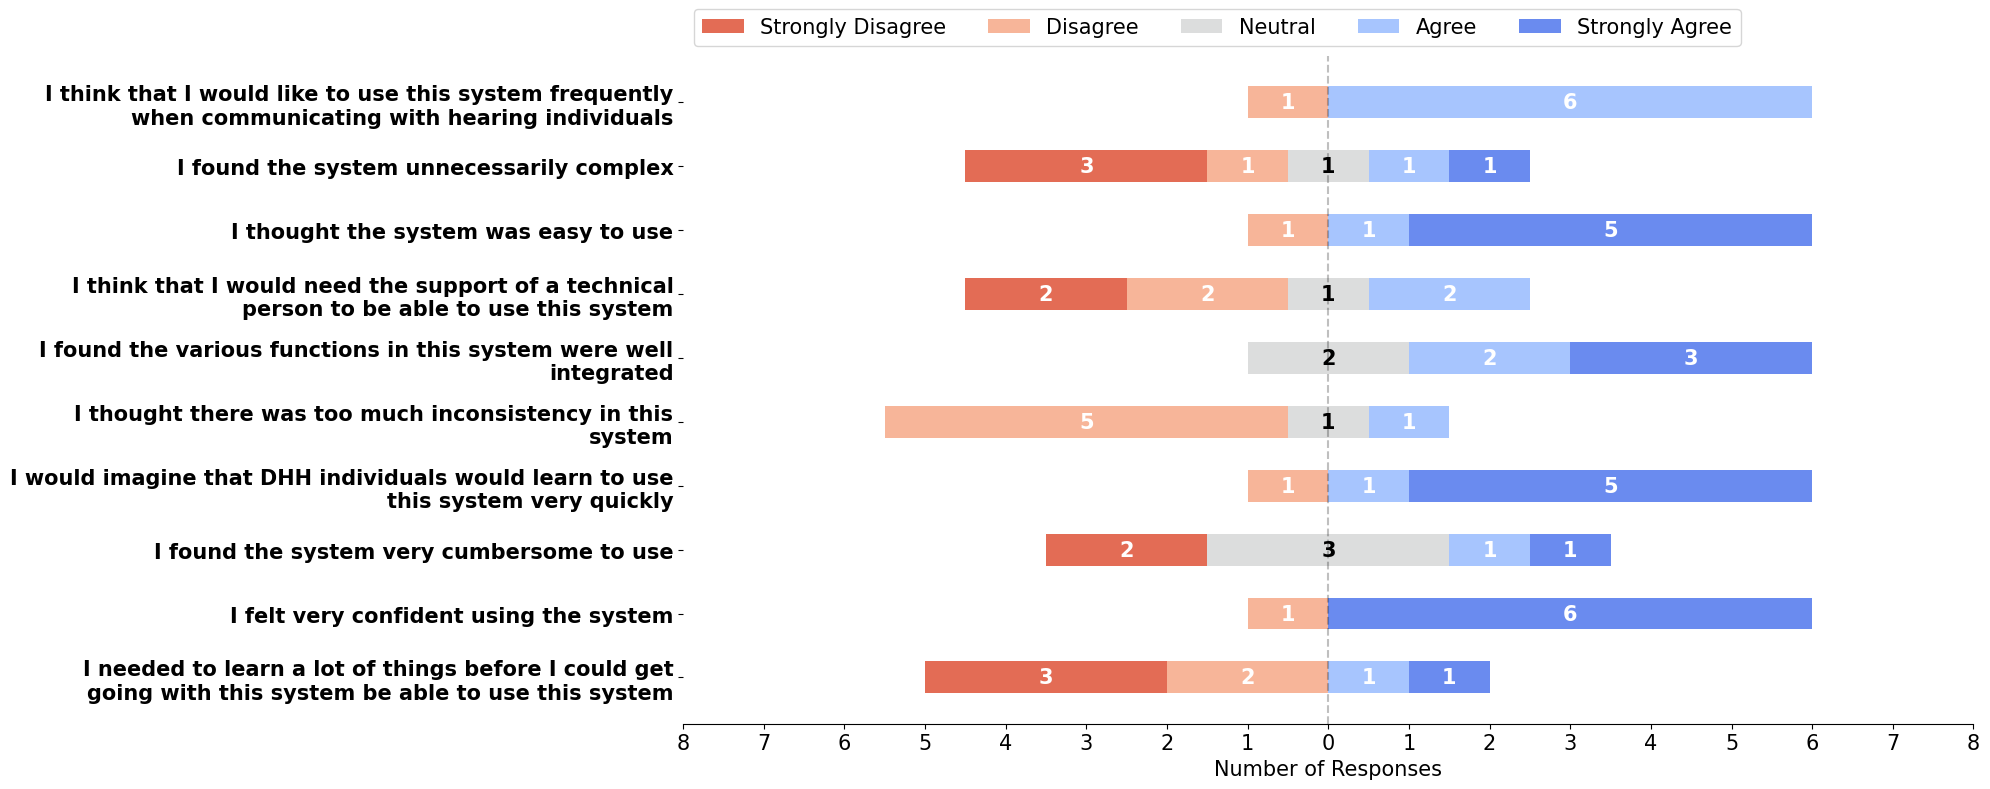

In [207]:
def survey(results, category_names):
    """
    Parameters
    ----------
    results : dict
        A mapping from question labels to a list of answers per category.
        It is assumed all lists contain the same number of entries and that
        it matches the length of *category_names*. The order is assumed
        to be from 'Strongly disagree' to 'Strongly aisagree'
    category_names : list of str
        The category labels.
    """
    
    labels = list(results.keys())
    data = np.array(list(results.values()))
    data_cum = data.cumsum(axis=1)
    middle_index = data.shape[1]//2
    offsets = data[:, range(middle_index)].sum(axis=1) + data[:, middle_index]/2
    
    # Color Mapping
    category_colors = plt.get_cmap('coolwarm_r')(
        np.linspace(0.15, 0.85, data.shape[1]))

    fontsize = 15
    
    fig, ax = plt.subplots(figsize=(20, 8))
    
    # Plot Bars
    for i, (colname, color) in enumerate(zip(category_names, category_colors)):
        widths = data[:, i]
        starts = data_cum[:, i] - widths - offsets
        rects = ax.barh(labels, widths, left=starts, height=0.5,
                        label=colname, color=color)
                # Add value labels inside bars
        for j, (width, start) in enumerate(zip(widths, starts)):
            # Calculate position for text
            if width == 0: continue
            text_x = start + width/2
            text_y = j
       
            # Add text with the actual value
            ax.text(text_x, text_y, f'{width}', 
                   ha='center', va='center', 
                   color='white' if i != 2 else 'black',  # Use black for middle category
                   fontweight='bold', fontsize=15)
    
    # Add Zero Reference Line
    ax.axvline(0, linestyle='--', color='black', alpha=.25)
    
    # X Axis
    ax.set_xlim(-8, 8)
    ax.set_xticks(np.arange(-8, 9, 1))
    ax.xaxis.set_major_formatter(lambda x, pos: str(abs(int(x))))
    ax.tick_params(axis='x', labelsize=fontsize)  # <--- Bigger x-axis tick labels

    # Y Axis
    ax.invert_yaxis()
    ax.tick_params(axis='y', labelsize=fontsize)  # <--- Bigger x-axis tick labels

    
    # Remove spines
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    # Ledgend
    ax.legend(ncol=len(category_names), bbox_to_anchor=(0, 1),
              loc='lower left', fontsize=fontsize)
    ax.set_xlabel("Number of Responses", fontsize = fontsize)
    for label in ax.get_yticklabels():label.set_fontweight('bold')
    
    # Set Background Color
    fig.set_facecolor('#FFFFFF')
    fig.tight_layout()
    fig.savefig('sus_questions_ar.png')

    return fig, ax


fig, ax = survey(sus_answers_category_count, categories)
plt.show()

# Next we do NASA TLX

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_grouped_boxplots_from_dicts(group1_dict, group2_dict, group1_label='Group 1', group2_label='Group 2', ylabel='Value', 
                                     output_file='grouped_boxplot.png',
                                     colors=None, hatch='//'):
    """
    Plots side-by-side boxplots using two dictionaries, where keys are category labels and values are data lists.

    Parameters:
        group1_dict (dict): Keys are category labels, values are lists of data for Group 1.
        group2_dict (dict): Keys are category labels, values are lists of data for Group 2.
        group1_label (str): Label for Group 1 (used in legend).
        group2_label (str): Label for Group 2 (used in legend).
        title (str): Title of the plot.
        ylabel (str): Label for the Y-axis.
        output_file (str): Filename to save the output plot.
        colors (list): Optional list of colors for the boxes.
        hatch (str): Hatch pattern for Group 2.
    """
    assert group1_dict.keys() == group2_dict.keys(), "Both groups must have the same category keys"
    
    category_labels = list(group1_dict.keys())
    num_categories = len(category_labels)

    fig, ax = plt.subplots(figsize=(24, 8))

    # Font sizes
    label_fontsize = 30
    tick_fontsize = 28

    # Position settings
    gap = 1.0  # Space between groups
    offset = 0.15  # Offset between group1 and group2 boxplots
    positions = []
    data = []

    for i, label in enumerate(category_labels):
        base = i * gap + 1
        positions.extend([base - offset, base + offset])
        data.extend([group1_dict[label], group2_dict[label]])

    # Assign colors
    if not colors:
        colors = ['lightblue'] * len(data)
    if colors and len(colors) == len(group1_dict.keys()):
        print("hello")
        colors_bruh = [colors[i // 2] for i in range(len(data))]
        colors = colors_bruh

    bp = ax.boxplot(data, positions=positions, patch_artist=True, widths=0.25)
    print("len data", len(data))
    for i, patch in enumerate(bp['boxes']):
        print(i)
        patch.set_facecolor(colors[i])
        patch.set_linewidth(1.5)
        patch.set_edgecolor('black')
        if i % 2 == 1:  # Group 2 gets the hatch
            patch.set_hatch(hatch)

    # Set x-axis
    tick_positions = [i * gap + 1 for i in range(num_categories)]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(category_labels, fontsize=tick_fontsize)

    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.tick_params(axis='y', labelsize=tick_fontsize)

    ax.set_xlim(min(positions) - 0.3, max(positions) + 0.3)

    # Legend
    legend_elements = [
        Patch(facecolor='white', edgecolor='black', label=group1_label),
        Patch(facecolor='white', edgecolor='black', hatch=hatch, label=group2_label)
    ]
    for median in bp['medians']:
        median.set_linewidth(2)           # Thicker line

    ax.legend(handles=legend_elements, loc='upper left', fontsize=tick_fontsize, title_fontsize=label_fontsize,ncols=2)

    plt.savefig(output_file, dpi=300, bbox_inches='tight', pad_inches=0)
    plt.tight_layout(pad=0)
    plt.show()


In [11]:
ar_restaurant_nasa_tlx_participants = {
    1: [int(i) for i in "3	3	1	5	6	2".split()],
    2: [int(i) for i in "2	1	1	2	2	2".split()],
3: [int(i) for i in "1	1	1	1	1	1".split()], 
    4: [int(i) for i in "4	4	4	2	3	5".split()], 
    5: [int(i) for i in "1	1	1	1	2	1".split()], 
    6: [int(i) for i in "1	1	1	1	2	1".split()], 
    7: [int(i) for i in "5	4	2	1	7	1".split()], 
}

social_nasa_tlx_str = """
3	1	4	5	3	2
1	1	1	2	1	1
2	2	1	1	2	1
6	6	3	5	6	2
2	1	1	6	4	2
2	1	1	1	6	1
5	4	2	2	6	2
"""
social_nasa_tlx = social_nasa_tlx_str[1: -1]
social_nasa_tlx_per_participant = social_nasa_tlx.split('\n')
ar_social_nasa_tlx_participants = dict()
for i in range(1, 8): 
    ar_social_nasa_tlx_participants[i] = [int(i) for i in social_nasa_tlx_per_participant[i - 1].split()]
    

In [12]:
ar_social_nasa_tlx_participants

{1: [3, 1, 4, 5, 3, 2],
 2: [1, 1, 1, 2, 1, 1],
 3: [2, 2, 1, 1, 2, 1],
 4: [6, 6, 3, 5, 6, 2],
 5: [2, 1, 1, 6, 4, 2],
 6: [2, 1, 1, 1, 6, 1],
 7: [5, 4, 2, 2, 6, 2]}

In [13]:
ar_social_nasa_tlx = dict()
ar_restaurant_nasa_tlx = dict()

nasa_tlx_categories = [
    "Mental Demand", 
    "Physical Demand", 
    "Temporal Demand", 
    "Performance", 
    "Effort", 
    "Frustration", 
]
for i, ca in enumerate(nasa_tlx_categories):
    ar_social_nasa_tlx[ca] = []
    ar_restaurant_nasa_tlx[ca] = []
    for participant_number in range(1, 8):
        ar_social_nasa_tlx[ca].append(ar_social_nasa_tlx_participants[participant_number][i])
        ar_restaurant_nasa_tlx[ca].append(ar_restaurant_nasa_tlx_participants[participant_number][i])


In [14]:
ar_social_nasa_tlx

{'Mental Demand': [3, 1, 2, 6, 2, 2, 5],
 'Physical Demand': [1, 1, 2, 6, 1, 1, 4],
 'Temporal Demand': [4, 1, 1, 3, 1, 1, 2],
 'Performance': [5, 2, 1, 5, 6, 1, 2],
 'Effort': [3, 1, 2, 6, 4, 6, 6],
 'Frustration': [2, 1, 1, 2, 2, 1, 2]}

In [15]:
ar_restaurant_nasa_tlx

{'Mental Demand': [3, 2, 1, 4, 1, 1, 5],
 'Physical Demand': [3, 1, 1, 4, 1, 1, 4],
 'Temporal Demand': [1, 1, 1, 4, 1, 1, 2],
 'Performance': [5, 2, 1, 2, 1, 1, 1],
 'Effort': [6, 2, 1, 3, 2, 2, 7],
 'Frustration': [2, 2, 1, 5, 1, 1, 1]}

hello
len data 12
0
1
2
3
4
5
6
7
8
9
10
11


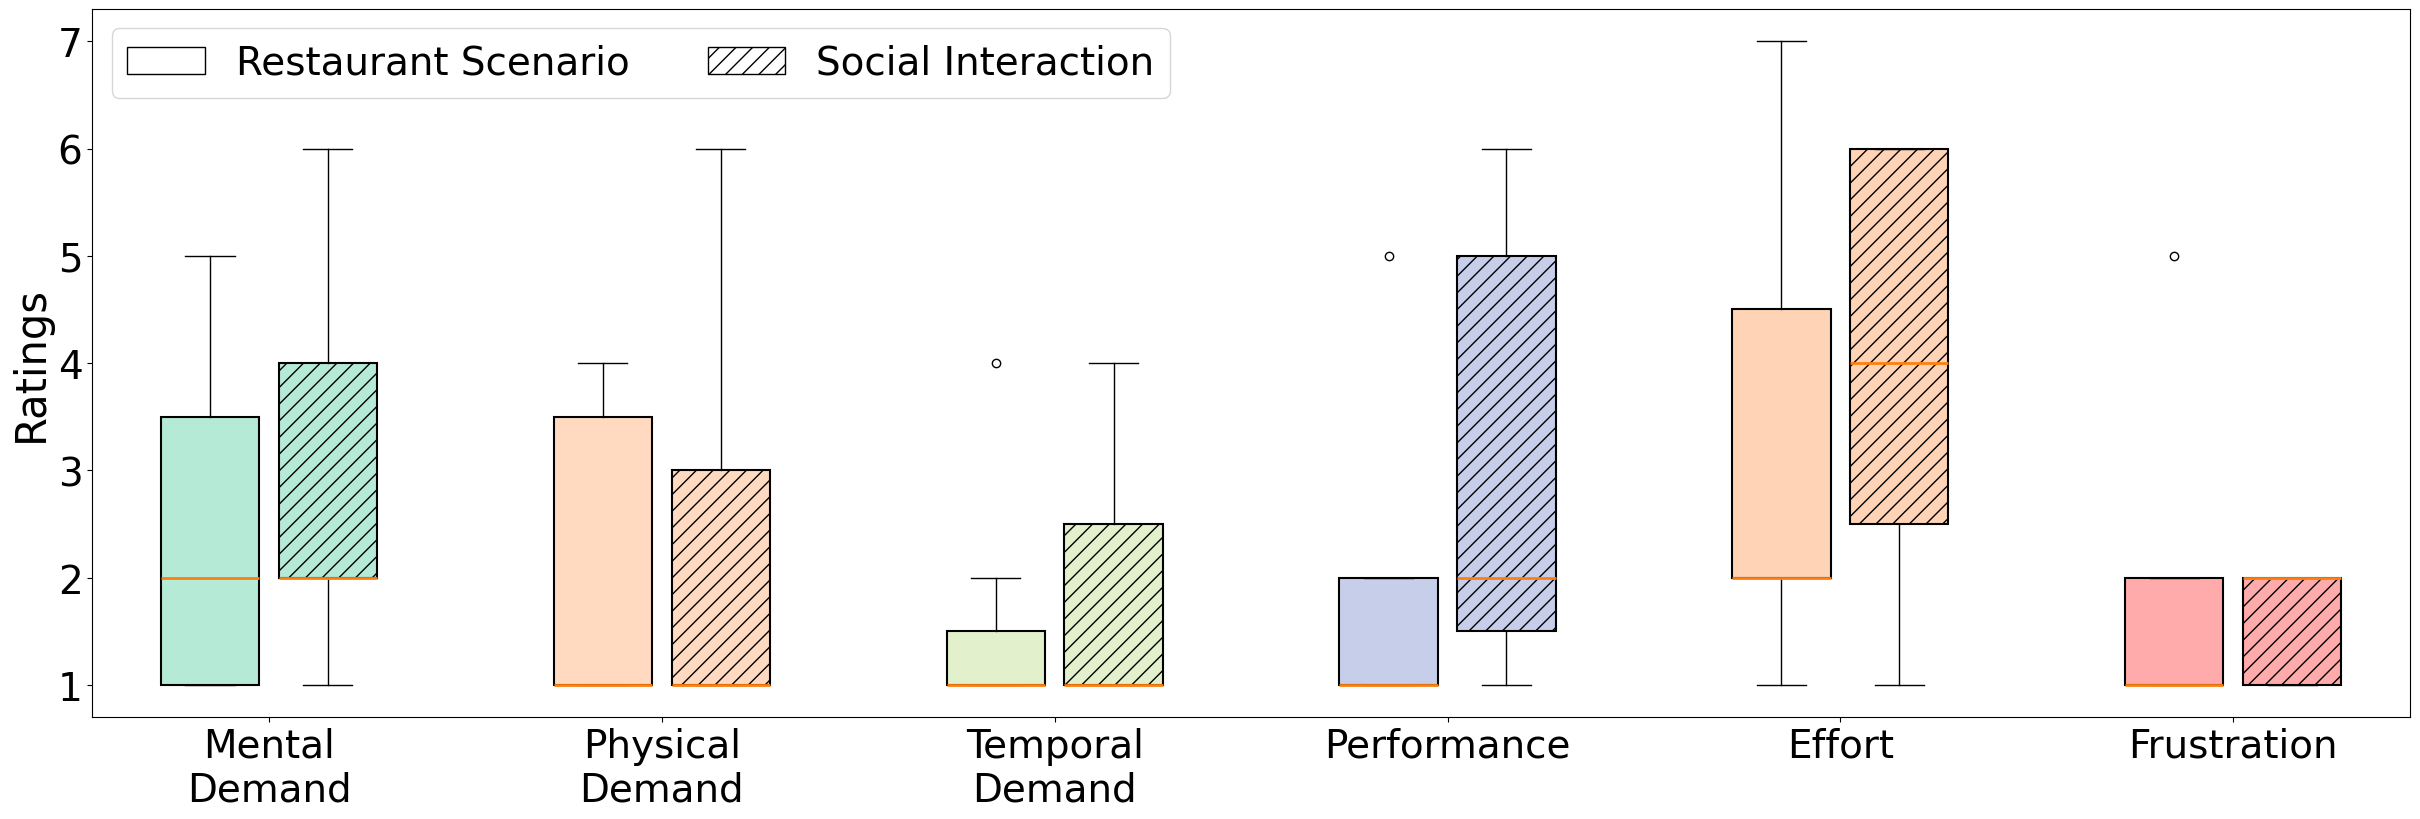

In [16]:
pastel_colors_alt = [
    "#B5EAD7",  # mint green
    "#FFDAC1",  # peach
    "#E2F0CB",  # pale green
    "#C7CEEA",  # soft lavender-blue
    "#FFD3B6",  # light apricot
    "#FFABAB"   # warm pastel pink
]

ar_restaurant_nasa_tlx_newline = dict()
for key, value in ar_restaurant_nasa_tlx.items(): 
    ar_restaurant_nasa_tlx_newline['\n'.join(textwrap.wrap(key, 5, break_long_words = False))] = value

ar_social_nasa_tlx_newline = dict()
for key, value in ar_social_nasa_tlx.items(): 
    ar_social_nasa_tlx_newline['\n'.join(textwrap.wrap(key, 5, break_long_words = False))] = value


plot_grouped_boxplots_from_dicts(ar_restaurant_nasa_tlx_newline, 
                                 ar_social_nasa_tlx_newline, 
                                 group1_label = 'Restaurant Scenario', 
                                 group2_label = "Social Interaction", 
                                 ylabel = "Ratings",
                                 colors = pastel_colors_alt, 
                                 output_file = "nasa_tlx_scenario_comparison.png"
                                 
                                 
                                )

In [17]:
ar_combined_nasa_tlx = dict()
for key, value in ar_social_nasa_tlx.items():
    ar_combined_nasa_tlx[key] = value + ar_restaurant_nasa_tlx[key]
    

In [18]:
ar_combined_nasa_tlx

{'Mental Demand': [3, 1, 2, 6, 2, 2, 5, 3, 2, 1, 4, 1, 1, 5],
 'Physical Demand': [1, 1, 2, 6, 1, 1, 4, 3, 1, 1, 4, 1, 1, 4],
 'Temporal Demand': [4, 1, 1, 3, 1, 1, 2, 1, 1, 1, 4, 1, 1, 2],
 'Performance': [5, 2, 1, 5, 6, 1, 2, 5, 2, 1, 2, 1, 1, 1],
 'Effort': [3, 1, 2, 6, 4, 6, 6, 6, 2, 1, 3, 2, 2, 7],
 'Frustration': [2, 1, 1, 2, 2, 1, 2, 2, 2, 1, 5, 1, 1, 1]}

In [19]:
phone_combined_nasa_tlx = dict()
phone_combined_nasa_tlx_str = """
1	5	2	1	2	1
1	1	5	1	2	1
3	2	3	3	5	3
6	6	1	7	6	2
1	1	1	1	1	1
1	1	1	1	1	1
4	2	1	2	6	2
3	1	4	5	3	2
1	3	5	3	5	2
3	2	2	3	3	2
5	6	6	7	6	2
1	1	1	1	1	1
1	1	2	1	1	1
1	1	1	1	7	1
"""

phone_combined_nasa_tlx_str = phone_combined_nasa_tlx_str[1: -1]
phone_combined_nasa_tlx_per_participant = phone_combined_nasa_tlx_str.split('\n')
phone_combined_nasa_tlx_participants = dict()

for i in range(1, 15): 
    phone_combined_nasa_tlx_participants[i] = [int(i) for i in phone_combined_nasa_tlx_per_participant[i - 1].split()]

for i, ca in enumerate(nasa_tlx_categories):
    phone_combined_nasa_tlx[ca] = []
    for participant_number in range(1, 15):
        phone_combined_nasa_tlx[ca].append(phone_combined_nasa_tlx_participants[participant_number][i])


In [20]:
phone_combined_nasa_tlx

{'Mental Demand': [1, 1, 3, 6, 1, 1, 4, 3, 1, 3, 5, 1, 1, 1],
 'Physical Demand': [5, 1, 2, 6, 1, 1, 2, 1, 3, 2, 6, 1, 1, 1],
 'Temporal Demand': [2, 5, 3, 1, 1, 1, 1, 4, 5, 2, 6, 1, 2, 1],
 'Performance': [1, 1, 3, 7, 1, 1, 2, 5, 3, 3, 7, 1, 1, 1],
 'Effort': [2, 2, 5, 6, 1, 1, 6, 3, 5, 3, 6, 1, 1, 7],
 'Frustration': [1, 1, 3, 2, 1, 1, 2, 2, 2, 2, 2, 1, 1, 1]}

Restaurant scenario data
Mental Demand
Median is  2.0
Quartile 75%:  3.5
Quartile 25%:  1.0
IQR 2.5
Physical Demand
Median is  1.0
Quartile 75%:  3.5
Quartile 25%:  1.0
IQR 2.5
Temporal Demand
Median is  1.0
Quartile 75%:  1.5
Quartile 25%:  1.0
IQR 0.5
Performance
Median is  1.0
Quartile 75%:  2.0
Quartile 25%:  1.0
IQR 1.0
Effort
Median is  2.0
Quartile 75%:  4.5
Quartile 25%:  2.0
IQR 2.5
Frustration
Median is  1.0
Quartile 75%:  2.0
Quartile 25%:  1.0
IQR 1.0
Social scenario data
Mental Demand
Median is  2.0
Quartile 75%:  4.0
Quartile 25%:  2.0
IQR 2.0
Physical Demand
Median is  1.0
Quartile 75%:  3.0
Quartile 25%:  1.0
IQR 2.0
Temporal Demand
Median is  1.0
Quartile 75%:  2.5
Quartile 25%:  1.0
IQR 1.5
Performance
Median is  2.0
Quartile 75%:  5.0
Quartile 25%:  1.5
IQR 3.5
Effort
Median is  4.0
Quartile 75%:  6.0
Quartile 25%:  2.5
IQR 3.5
Frustration
Median is  2.0
Quartile 75%:  2.0
Quartile 25%:  1.0
IQR 1.0
len data 12
0
1
2
3
4
5
6
7
8
9
10
11


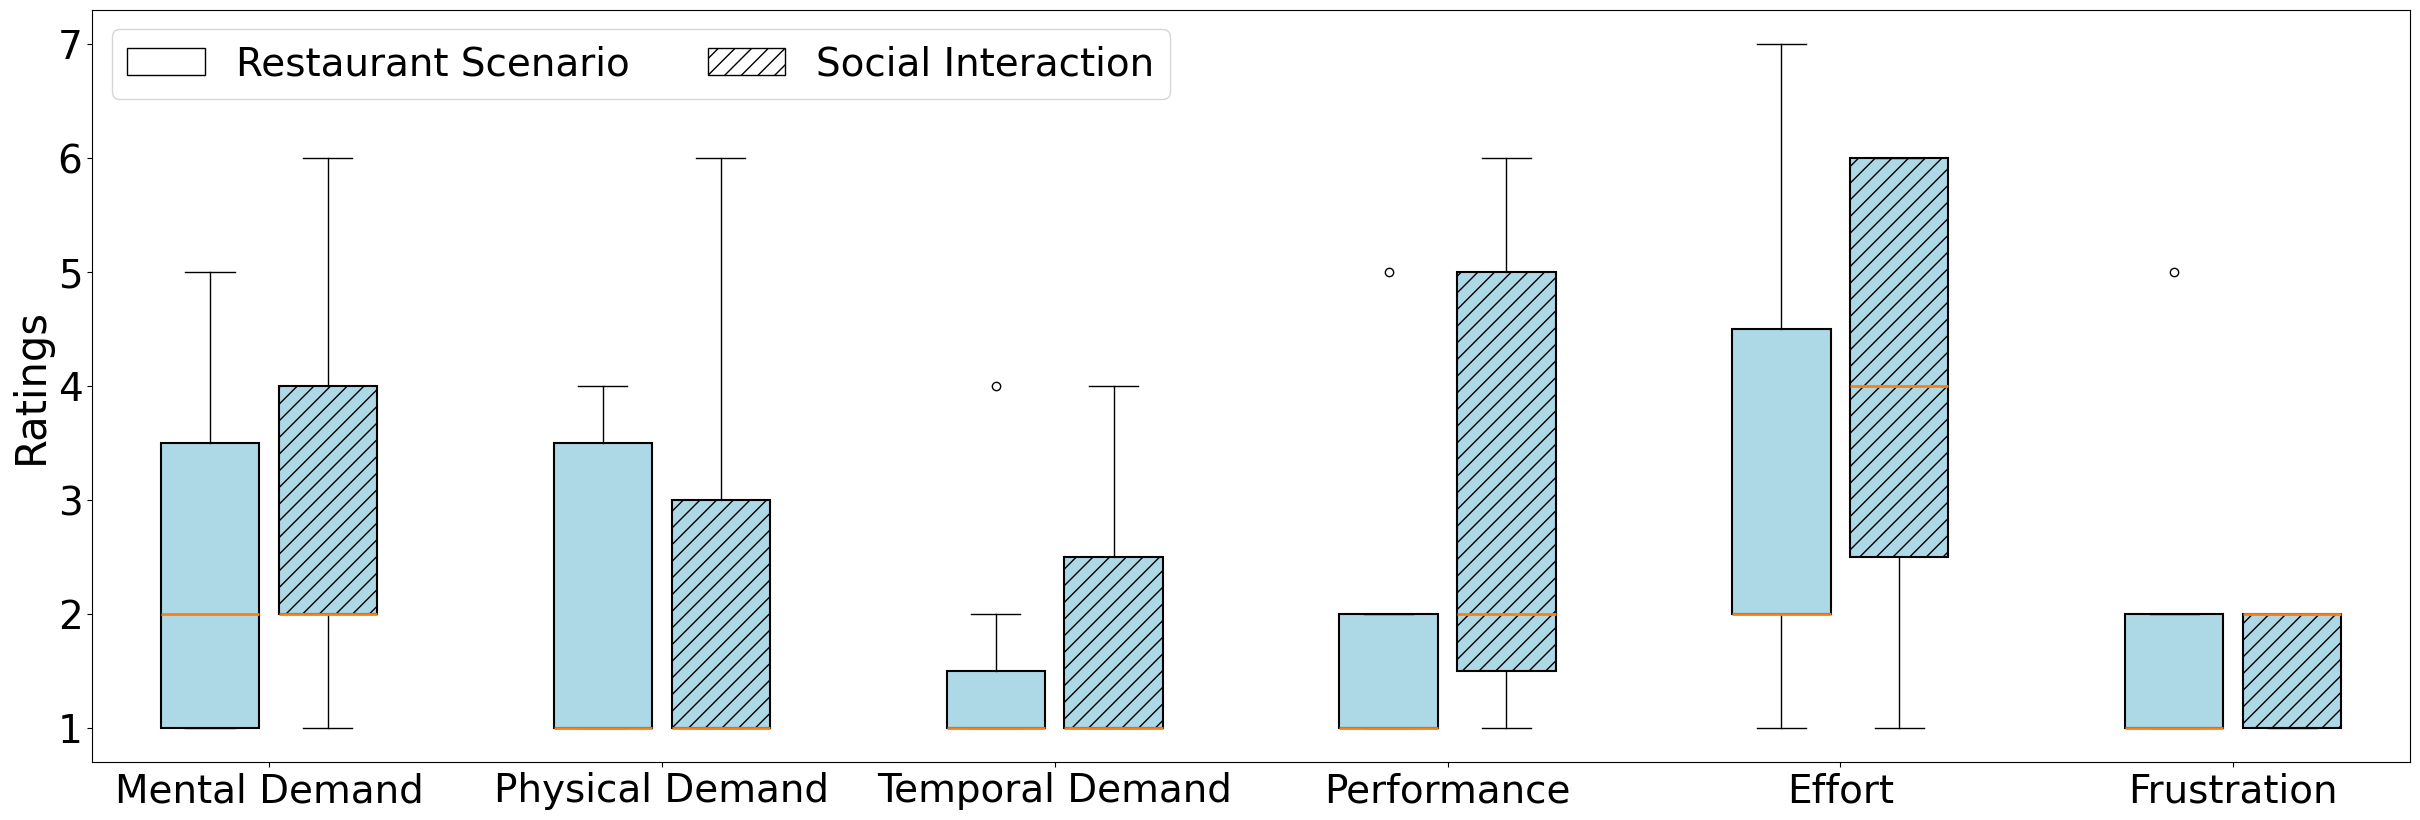

In [92]:
print("Restaurant scenario data")
for question, data in ar_restaurant_nasa_tlx.items():
    q75, q25 = np.percentile(data, [75 ,25])
    iqr = q75 - q25
    print(question) 
    print("Median is ",np.median(data))
    print("Quartile 75%: ", q75)
    print("Quartile 25%: " ,q25)
    print("IQR", iqr)
print("Social scenario data")
for question, data in ar_social_nasa_tlx.items():
    q75, q25 = np.percentile(data, [75 ,25])
    iqr = q75 - q25
    print(question) 
    print("Median is ",np.median(data))
    print("Quartile 75%: ", q75)
    print("Quartile 25%: " ,q25)
    print("IQR", iqr)

plot_grouped_boxplots_from_dicts(ar_restaurant_nasa_tlx, 
                                 ar_social_nasa_tlx, 
                                 group1_label = 'Restaurant Scenario', 
                                 group2_label = "Social Interaction", 
                                 ylabel = "Ratings",
                                 output_file = "nasa_tlx.png"
                                )

In [22]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_grouped_boxplots_two_colors(group1_dict, group2_dict,
                                     group1_label='Group 1', group2_label='Group 2',
                                     ylabel='Value',
                                     output_file='grouped_boxplot.png',
                                     colors_group1=None, colors_group2=None, 
                                     figsize = (24, 8), 
                                     go_from_one=False,
                                     legend_loc = 'upper right'
                                    ):
    """
    Plots side-by-side boxplots using two dictionaries. Each group can have its own color palette.

    Parameters:
        group1_dict (dict): Keys = category labels, values = data lists for group 1.
        group2_dict (dict): Same keys as group1_dict, for group 2.
        group1_label (str): Label for the first group.
        group2_label (str): Label for the second group.
        title (str): Title for the plot.
        ylabel (str): Y-axis label.
        output_file (str): Filename to save the plot.
        colors_group1 (list): List of fill colors for group 1 boxes.
        colors_group2 (list): List of fill colors for group 2 boxes.
    """
    assert group1_dict.keys() == group2_dict.keys(), "Both groups must have the same category keys"
    
    category_labels = list(group1_dict.keys())
    num_categories = len(category_labels)

    fig, ax = plt.subplots(figsize=figsize)

    # Font sizes
    label_fontsize = 30
    tick_fontsize = 28

    # Position setup
    gap = 1.0
    offset = 0.15
    positions = []
    data = []

    for i, label in enumerate(category_labels):
        base = i * gap + 1
        positions.extend([base - offset, base + offset])
        data.extend([group1_dict[label], group2_dict[label]])

    total_boxes = len(data)

    # Repeat or slice color lists as needed
    if not colors_group1:
        colors_group1 = ['lightblue'] * num_categories
    if not colors_group2:
        colors_group2 = ['lightgreen'] * num_categories
    colors = []
    for i in range(num_categories):
        colors.append(colors_group1[i % len(colors_group1)])
        colors.append(colors_group2[i % len(colors_group2)])

    bp = ax.boxplot(data, positions=positions, patch_artist=True, widths=0.25)

    for i, patch in enumerate(bp['boxes']):
        patch.set_facecolor(colors[i])
        patch.set_linewidth(1.5)
        patch.set_edgecolor('black')

    # Set x-axis
    tick_positions = [i * gap + 1 for i in range(num_categories)]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(category_labels, fontsize=tick_fontsize)

    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.tick_params(axis='y', labelsize=tick_fontsize)
    ax.set_xlim(min(positions) - 0.3, max(positions) + 0.3)
    if go_from_one: 
        ax.set_ylim(ymin=1)


    # Legend
    legend_elements = [
        Patch(facecolor=colors_group1[0], edgecolor='black', label=group1_label),
        Patch(facecolor=colors_group2[0], edgecolor='black', label=group2_label)
    ]
    ax.legend(handles=legend_elements, loc=legend_loc, fontsize=tick_fontsize, title_fontsize=label_fontsize)
    for median in bp['medians']:
        median.set_linewidth(2)           # Thicker line

    plt.savefig(output_file, dpi=300, bbox_inches='tight', pad_inches=0)
    plt.tight_layout(pad=0)
    plt.show()


AR glasses nasa tlx data
Mental
Demand
Median is  2.0
Quartile 75%:  3.75
Quartile 25%:  1.25
IQR 2.5
Physical
Demand
Median is  1.0
Quartile 75%:  3.75
Quartile 25%:  1.0
IQR 2.75
Temporal
Demand
Median is  1.0
Quartile 75%:  2.0
Quartile 25%:  1.0
IQR 1.0
Performance
Median is  2.0
Quartile 75%:  4.25
Quartile 25%:  1.0
IQR 3.25
Effort
Median is  3.0
Quartile 75%:  6.0
Quartile 25%:  2.0
IQR 4.0
Frustration
Median is  1.5
Quartile 75%:  2.0
Quartile 25%:  1.0
IQR 1.0
phone typing nasa tlx data
Mental
Demand
Median is  1.0
Quartile 75%:  3.0
Quartile 25%:  1.0
IQR 2.0
Physical
Demand
Median is  1.5
Quartile 75%:  2.75
Quartile 25%:  1.0
IQR 1.75
Temporal
Demand
Median is  2.0
Quartile 75%:  3.75
Quartile 25%:  1.0
IQR 2.75
Performance
Median is  1.5
Quartile 75%:  3.0
Quartile 25%:  1.0
IQR 2.0
Effort
Median is  3.0
Quartile 75%:  5.75
Quartile 25%:  1.25
IQR 4.5
Frustration
Median is  1.5
Quartile 75%:  2.0
Quartile 25%:  1.0
IQR 1.0


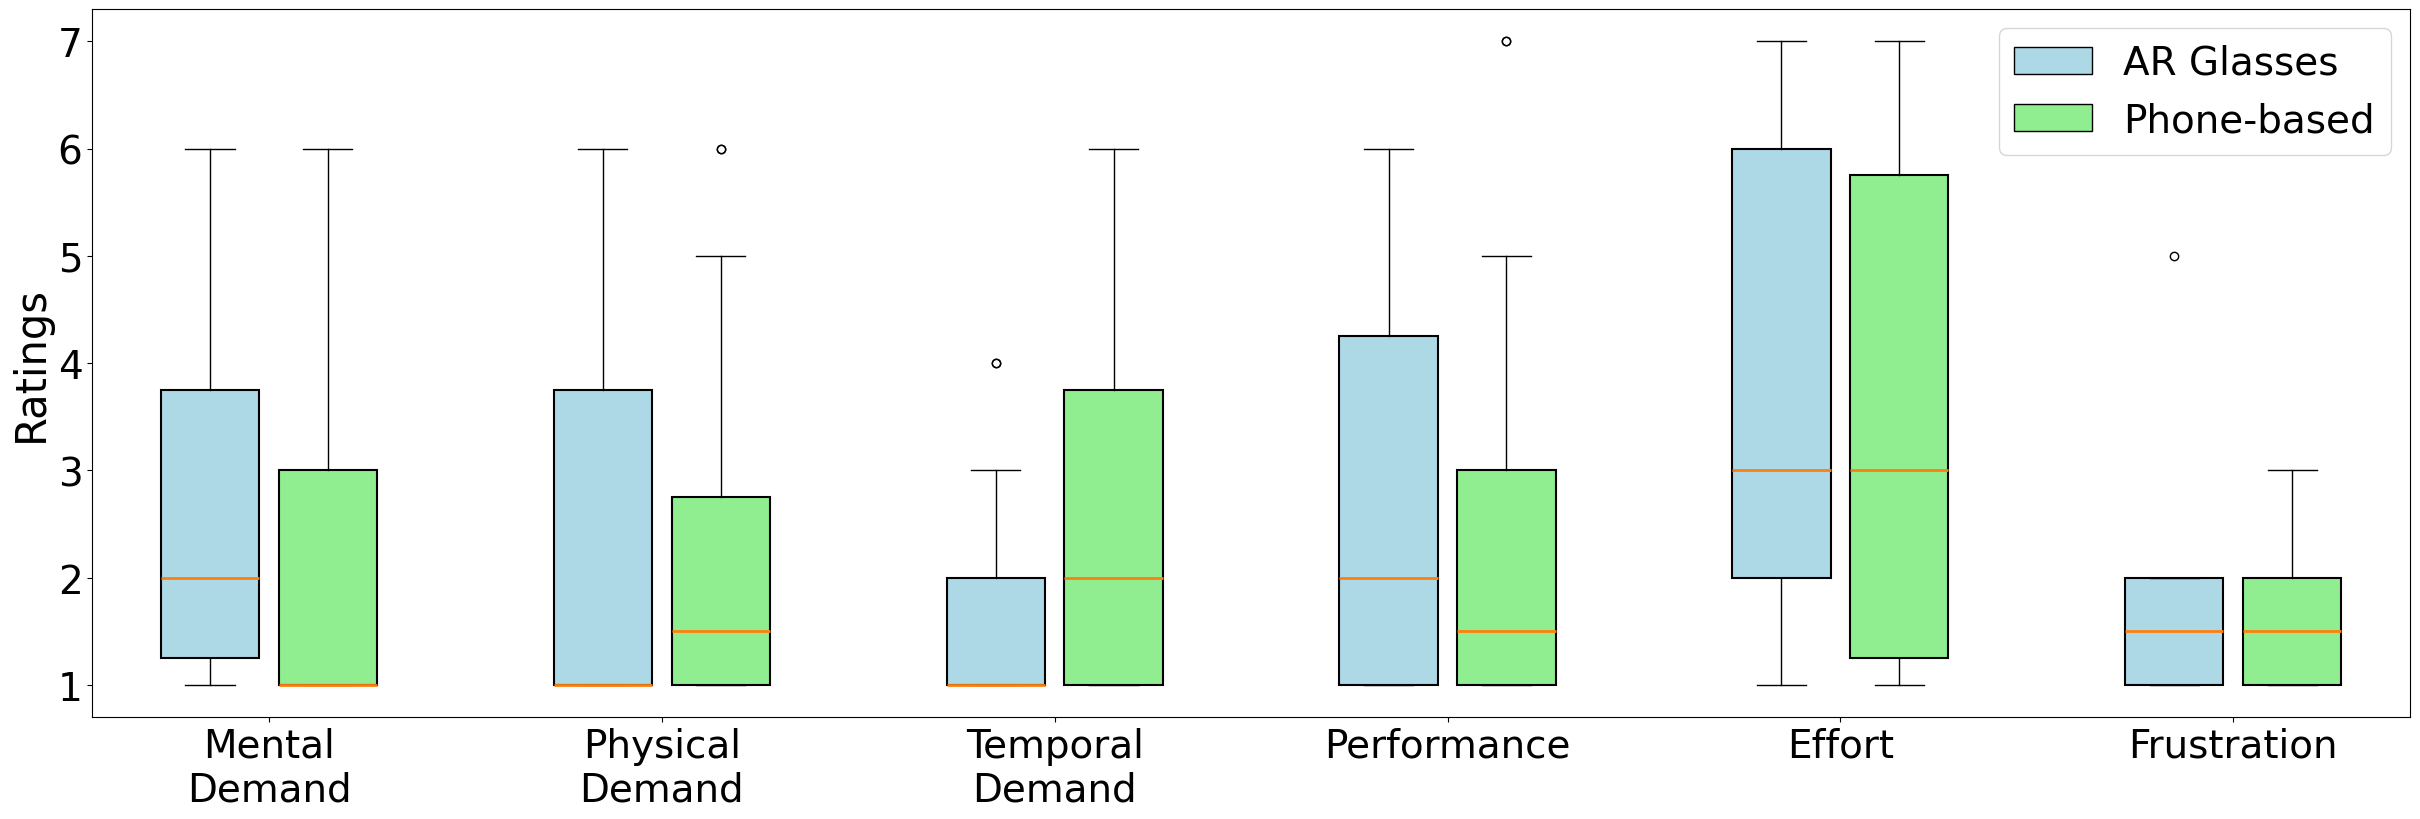

In [93]:
ar_combined_nasa_tlx_newline = dict()
for key, value in ar_combined_nasa_tlx.items(): 
    ar_combined_nasa_tlx_newline['\n'.join(textwrap.wrap(key, 5, break_long_words = False))] = value

phone_combined_nasa_tlx_newline = dict()
for key, value in phone_combined_nasa_tlx.items(): 
    phone_combined_nasa_tlx_newline['\n'.join(textwrap.wrap(key, 5, break_long_words = False))] = value

print("AR glasses nasa tlx data")
for question, data in ar_combined_nasa_tlx_newline.items():
    q75, q25 = np.percentile(data, [75 ,25])
    iqr = q75 - q25
    print(question) 
    print("Median is ",np.median(data))
    print("Quartile 75%: ", q75)
    print("Quartile 25%: " ,q25)
    print("IQR", iqr)
print("phone typing nasa tlx data")
for question, data in phone_combined_nasa_tlx_newline.items():
    q75, q25 = np.percentile(data, [75 ,25])
    iqr = q75 - q25
    print(question) 
    print("Median is ",np.median(data))
    print("Quartile 75%: ", q75)
    print("Quartile 25%: " ,q25)
    print("IQR", iqr)



plot_grouped_boxplots_two_colors(ar_combined_nasa_tlx_newline, phone_combined_nasa_tlx_newline, group1_label="AR Glasses", group2_label = "Phone-based", ylabel="Ratings", output_file = "nasa_tlx_ar_phone.png")

In [24]:
survey_label_str = """
Restaurant Experience
Restaurant Experience
Social Interaction
Restaurant Experience
Social Interaction
Restaurant Experience
Social Interaction
Social Interaction
Social Interaction
Restaurant Experience
Social Interaction
Restaurant Experience
Social Interaction
Restaurant Experience
"""
survey_label_str = survey_label_str[1:-1]
survey_label = [label for label in survey_label_str.split('\n')]

In [25]:
survey_label

['Restaurant Experience',
 'Restaurant Experience',
 'Social Interaction',
 'Restaurant Experience',
 'Social Interaction',
 'Restaurant Experience',
 'Social Interaction',
 'Social Interaction',
 'Social Interaction',
 'Restaurant Experience',
 'Social Interaction',
 'Restaurant Experience',
 'Social Interaction',
 'Restaurant Experience']

In [26]:
system_survey_questions_actual_str = """
Overall, how well did our AR user interface help convey your intended meaning during communication?	
WITHOUT signing, how well did the conversational option you chose from the suggestions help convey your intended meaning?	
AFTER signing, how well did the option you chose from the multiple translation results help convey your intended meaning?	
If you did not choose a suggested option, how easy was it to refine the options with signing?	
When signing, how much did seeing multiple translation results reduce your concerns about translation errors and help avoid miscommunication?
"""
system_survey_questions_str ="""
Q1: Overall effectiveness
Q2: Quick-SELECT-options clarity
Q3: SIGN-option clarity
Q4: Refinement ease
Q5: Error reassurance
"""
system_survey_questions_str = system_survey_questions_str[1: -1]
system_survey_questions = ['\n'.join(textwrap.wrap(q.rstrip(), 18,break_long_words=False))  for q in system_survey_questions_str.split('\n')]

system_survey_participants_all_scenarios_str = """
6	6	6	6	6
6	6	7	7	7
7	6	7	7	7
4	5	5	4	4
6	6	2	2	5
7	4	7	7	7
7	6	6	5	7
6	5	6	6	5
7	5	7	7	7
7	6	7	7	7
5	5	5	4	6
6	7	6	6	7
7	2	7	7	7
7	7	7	7	7
"""
system_survey_participants_all_scenarios_str = system_survey_participants_all_scenarios_str[1: -1]
print(system_survey_participants_all_scenarios_str)
system_survey_participants_all_scenarios = [[int(num) for num in q.split()] for q in system_survey_participants_all_scenarios_str.split('\n')]

print(system_survey_participants_all_scenarios)
print(len(system_survey_participants_all_scenarios))

system_survey_all_scenarios = dict()
system_survey_restaurant = dict()
system_survey_social = dict()
for question_i, question in enumerate(system_survey_questions): 
    system_survey_all_scenarios[question] = []
    system_survey_restaurant[question] = []
    system_survey_social[question] = []
    for pn in range(0, 14):
        system_survey_all_scenarios[question].append(system_survey_participants_all_scenarios[pn][question_i])
        if survey_label[pn] == "Restaurant Experience": 
            system_survey_restaurant[question].append(system_survey_participants_all_scenarios[pn][question_i])
        else: 
            system_survey_social[question].append(system_survey_participants_all_scenarios[pn][question_i])



6	6	6	6	6
6	6	7	7	7
7	6	7	7	7
4	5	5	4	4
6	6	2	2	5
7	4	7	7	7
7	6	6	5	7
6	5	6	6	5
7	5	7	7	7
7	6	7	7	7
5	5	5	4	6
6	7	6	6	7
7	2	7	7	7
7	7	7	7	7
[[6, 6, 6, 6, 6], [6, 6, 7, 7, 7], [7, 6, 7, 7, 7], [4, 5, 5, 4, 4], [6, 6, 2, 2, 5], [7, 4, 7, 7, 7], [7, 6, 6, 5, 7], [6, 5, 6, 6, 5], [7, 5, 7, 7, 7], [7, 6, 7, 7, 7], [5, 5, 5, 4, 6], [6, 7, 6, 6, 7], [7, 2, 7, 7, 7], [7, 7, 7, 7, 7]]
14


In [27]:
system_survey_social

{'Q1: Overall\neffectiveness': [7, 6, 7, 6, 7, 5, 7],
 'Q2: Quick-SELECT-\noptions clarity': [6, 6, 6, 5, 5, 5, 2],
 'Q3: SIGN-option\nclarity': [7, 2, 6, 6, 7, 5, 7],
 'Q4: Refinement\nease': [7, 2, 5, 6, 7, 4, 7],
 'Q5: Error\nreassurance': [7, 5, 7, 5, 7, 6, 7]}

In [28]:
system_survey_restaurant

{'Q1: Overall\neffectiveness': [6, 6, 4, 7, 7, 6, 7],
 'Q2: Quick-SELECT-\noptions clarity': [6, 6, 5, 4, 6, 7, 7],
 'Q3: SIGN-option\nclarity': [6, 7, 5, 7, 7, 6, 7],
 'Q4: Refinement\nease': [6, 7, 4, 7, 7, 6, 7],
 'Q5: Error\nreassurance': [6, 7, 4, 7, 7, 7, 7]}

In [29]:
system_survey_all_scenarios

{'Q1: Overall\neffectiveness': [6, 6, 7, 4, 6, 7, 7, 6, 7, 7, 5, 6, 7, 7],
 'Q2: Quick-SELECT-\noptions clarity': [6,
  6,
  6,
  5,
  6,
  4,
  6,
  5,
  5,
  6,
  5,
  7,
  2,
  7],
 'Q3: SIGN-option\nclarity': [6, 7, 7, 5, 2, 7, 6, 6, 7, 7, 5, 6, 7, 7],
 'Q4: Refinement\nease': [6, 7, 7, 4, 2, 7, 5, 6, 7, 7, 4, 6, 7, 7],
 'Q5: Error\nreassurance': [6, 7, 7, 4, 5, 7, 7, 5, 7, 7, 6, 7, 7, 7]}

In [30]:
system_survey

NameError: name 'system_survey' is not defined

{'Q1: Overall\neffectiveness': [6, 6, 4, 7, 7, 6, 7], 'Q2: Quick-SELECT-\noptions clarity': [6, 6, 5, 4, 6, 7, 7], 'Q3: SIGN-option\nclarity': [6, 7, 5, 7, 7, 6, 7], 'Q4: Refinement\nease': [6, 7, 4, 7, 7, 6, 7], 'Q5: Error\nreassurance': [6, 7, 4, 7, 7, 7, 7]}
Restaurant scenario data
Q1: Overall
effectiveness
Median is  6.0
Quartile 75%:  7.0
Quartile 25%:  6.0
IQR 1.0
Q2: Quick-SELECT-
options clarity
Median is  6.0
Quartile 75%:  6.5
Quartile 25%:  5.5
IQR 1.0
Q3: SIGN-option
clarity
Median is  7.0
Quartile 75%:  7.0
Quartile 25%:  6.0
IQR 1.0
Q4: Refinement
ease
Median is  7.0
Quartile 75%:  7.0
Quartile 25%:  6.0
IQR 1.0
Q5: Error
reassurance
Median is  7.0
Quartile 75%:  7.0
Quartile 25%:  6.5
IQR 0.5
Social scenario data
Q1: Overall
effectiveness
Median is  7.0
Quartile 75%:  7.0
Quartile 25%:  6.0
IQR 1.0
Q2: Quick-SELECT-
options clarity
Median is  5.0
Quartile 75%:  6.0
Quartile 25%:  5.0
IQR 1.0
Q3: SIGN-option
clarity
Median is  6.0
Quartile 75%:  7.0
Quartile 25%:  5.5
IQ

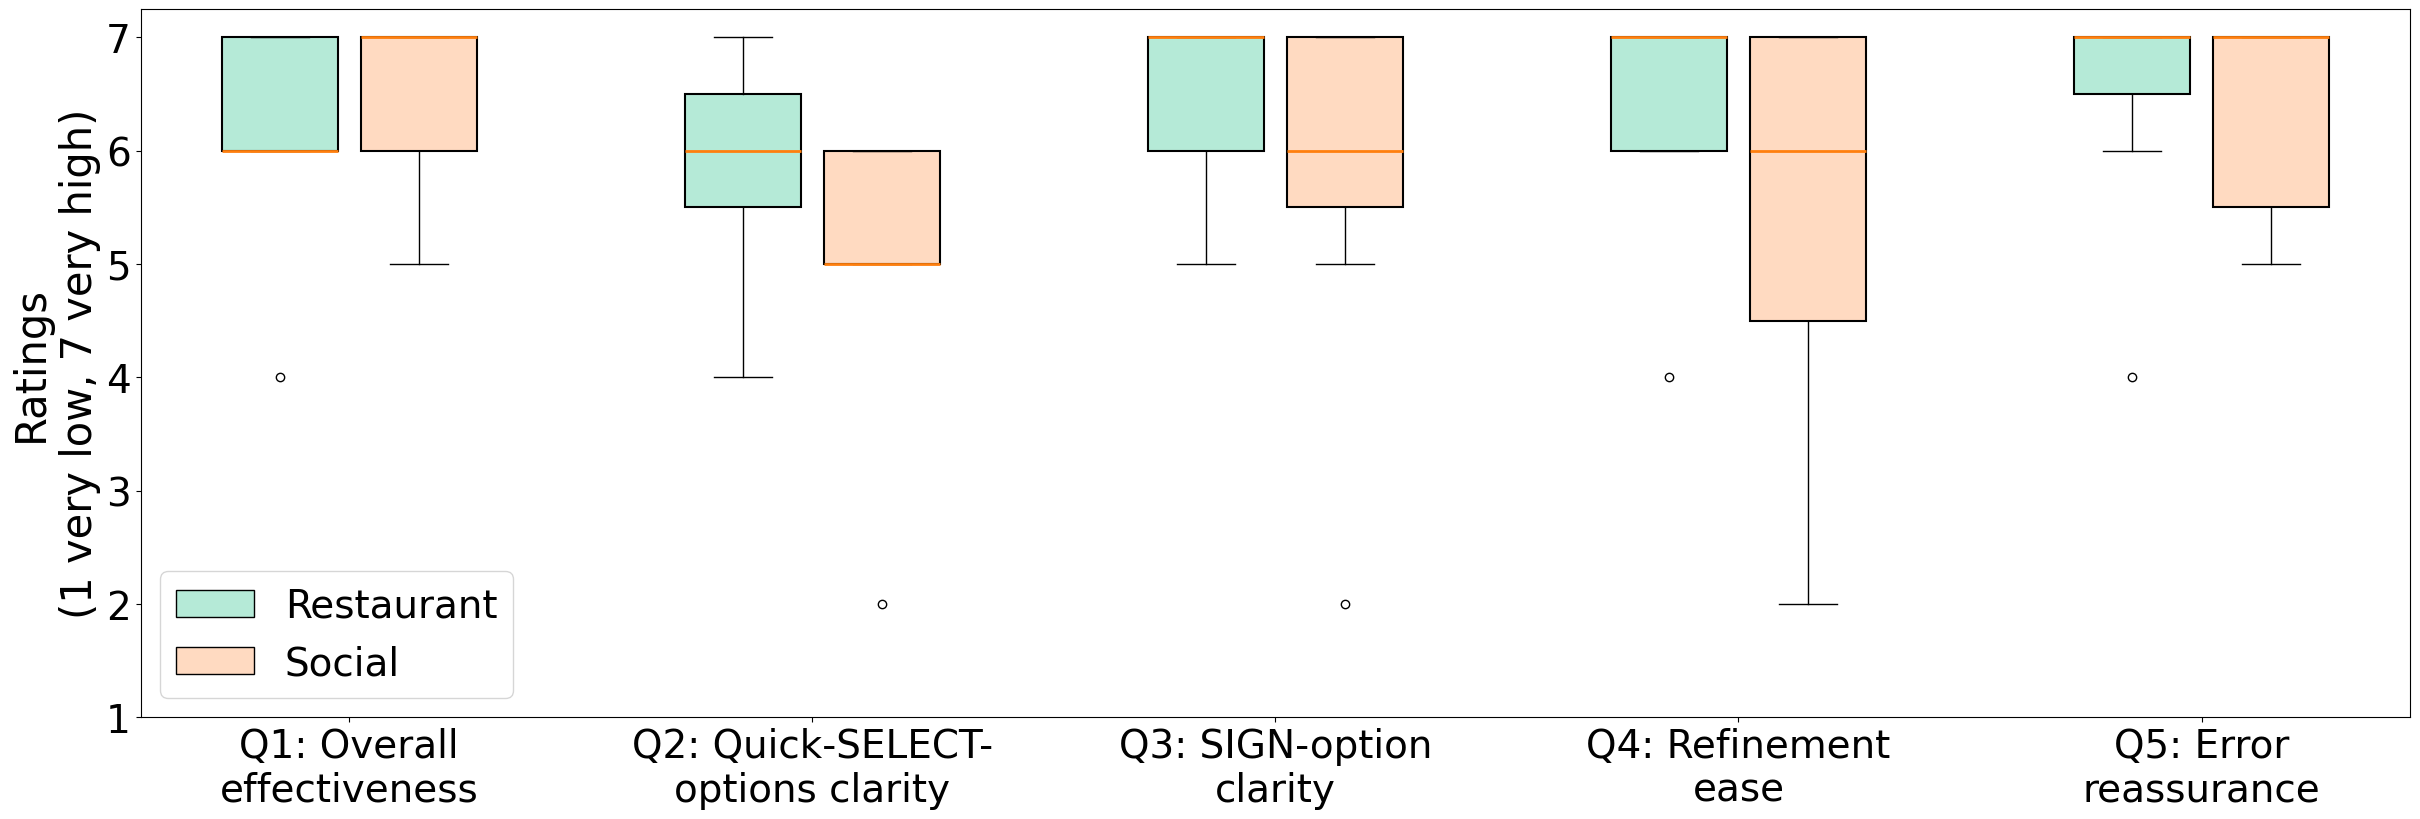

In [50]:
pastel_mint   = "#B5EAD7"  # minty green
pastel_peach  = "#FFDAC1"  # soft peachk

print(system_survey_restaurant)
print("Restaurant scenario data")
for question, data in system_survey_restaurant.items():
    q75, q25 = np.percentile(data, [75 ,25])
    iqr = q75 - q25
    print(question) 
    print("Median is ",np.median(data))
    print("Quartile 75%: ", q75)
    print("Quartile 25%: " ,q25)
    print("IQR", iqr)
print("Social scenario data")
for question, data in system_survey_social.items():
    q75, q25 = np.percentile(data, [75 ,25])
    iqr = q75 - q25
    print(question) 
    print("Median is ",np.median(data))
    print("Quartile 75%: ", q75)
    print("Quartile 25%: " ,q25)
    print("IQR", iqr)
plot_grouped_boxplots_two_colors(system_survey_restaurant, system_survey_social, group1_label="Restaurant", group2_label = "Social", ylabel="Ratings\n(1 very low, 7 very high)", output_file = "system_survey.png", colors_group1 = [pastel_mint], colors_group2 = [pastel_peach], go_from_one=True, legend_loc = "lower left")

In [ ]:
This figure contains ten boxplots total—two boxplots (Restaurant vs. Social) for each of five survey questions (Q1–Q5). Each boxplot shows a median rating on a 7-point Likert scale (1 = very low, 7 = very high) with an interquartile range (IQR) of 0.5.
Q1 (Overall effectiveness)

Restaurant: Median = 6.0; Quartiles = 6.0 ± 0.25 (IQR = 0.5)

Social: Median = 7.0; Quartiles = 7.0 ± 0.25 (IQR = 0.5)

Q2 (Quick-SELECT-options clarity)

Restaurant: Median = 6.0; Quartiles = 6.0 ± 0.25 (IQR = 0.5)

Social: Median = 5.0; Quartiles = 5.0 ± 0.25 (IQR = 0.5)

Q3 (SIGN-option clarity)

Restaurant: Median = 7.0; Quartiles = 7.0 ± 0.25 (IQR = 0.5)

Social: Median = 6.0; Quartiles = 6.0 ± 0.25 (IQR = 0.5)

Q4 (Refinement ease)

Restaurant: Median = 7.0; Quartiles = 7.0 ± 0.25 (IQR = 0.5)

Social: Median = 6.0; Quartiles = 6.0 ± 0.25 (IQR = 0.5)

Q5 (Error reassurance)

Restaurant: Median = 7.0; Quartiles = 7.0 ± 0.25 (IQR = 0.5)

Social: Median = 7.0; Quartiles = 7.0 ± 0.25 (IQR = 0.5)

Across questions, the Restaurant scenario scores tend to be higher in Q2, Q3, and Q4, while Social is higher in Q1, and both are equal for Q5. The narrow IQR in all boxplots (0.5) indicates relatively consistent responses in each scenario.

In [45]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_boxplot_single_dict(data_dict,
                              ylabel='Value',
                              output_file='single_group_boxplot.png',
                              colors=None,
                              figsize=(24, 8),
                              go_from_one=False,
                              legend_label=None,
                              legend_loc='upper right'):
    """
    Plots standard (non-grouped) boxplots using a single dictionary of data.
    
    Parameters:
        data_dict (dict): Keys = category labels, values = data lists.
        ylabel (str): Y-axis label.
        output_file (str): Filename to save the plot.
        colors (list): Optional list of fill colors for the boxes.
        figsize (tuple): Size of the plot.
        go_from_one (bool): If True, y-axis starts at 1.
        legend_label (str): Optional legend label.
        legend_loc (str): Location of the legend.
    """
    category_labels = list(data_dict.keys())
    data = list(data_dict.values())
    num_categories = len(category_labels)

    fig, ax = plt.subplots(figsize=figsize)

    # Font sizes
    label_fontsize = 30
    tick_fontsize = 28

    # Positions
    positions = list(range(1, num_categories + 1))

    # Assign colors
    if not colors:
        colors = ['lightblue'] * num_categories
    if len(colors) < num_categories:
        colors *= (num_categories // len(colors) + 1)
    colors = colors[:num_categories]

    # Create boxplot
    bp = ax.boxplot(data, positions=positions, patch_artist=True, widths=0.4)

    for i, patch in enumerate(bp['boxes']):
        patch.set_facecolor(colors[i])
        patch.set_linewidth(1.5)
        patch.set_edgecolor('black')

    for median in bp['medians']:
        median.set_linewidth(2)

    # Axes settings
    ax.set_xticks(positions)
    ax.set_xticklabels(category_labels, fontsize=tick_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)
    ax.tick_params(axis='y', labelsize=tick_fontsize)
    ax.set_xlim(min(positions) - 0.5, max(positions) + 0.5)
    if go_from_one:
        ax.set_ylim(bottom=1)

    # Optional legend
    if legend_label:
        legend_patch = Patch(facecolor=colors[0], edgecolor='black', label=legend_label)
        ax.legend(handles=[legend_patch], loc=legend_loc, fontsize=tick_fontsize, title_fontsize=label_fontsize)

    plt.tight_layout(pad=0)
    plt.savefig(output_file, dpi=300)

    plt.show()


In [46]:
ui_survey_questions_actual_str = """
How readable was the user interface displaying the recognized speech (blue background with white text)	
How would you rate the quality of the Automatic Speech Recognition system? Did it effectively help you understand what hearing individuals were saying
How readable was the user interface displaying the five options during the study? (The image is an example)
Overall, how accurately did the system recognize your ASL digit gestures for selection and confirmation?	
Overall, how easy was it to use ASL digit gestures to make selection and confirmation?	
How effectively did the progress bar help you perceive the timing or status of the spoken output?
"""
ui_survey_questions_str = """
Q1: ASR Readability
Q2: ASR Quality
Q3: Options Readability
Q4: Gesture Recognition Accuracy
Q5: Gesture Ease of Use
Q6: Progress Bar Usefulness
"""

ui_survey_questions_str = ui_survey_questions_str[1: -1]
ui_survey_questions = ['\n'.join(textwrap.wrap(q.rstrip(), 18,break_long_words=False))  for q in ui_survey_questions_str.split('\n')]



ui_survey_str= """
6	6	6	6	6	6
7	7	7	5	7	7
5	6	6	6	7	7
4	5	5	3	6	5
7	5	7	6	7	7
7	7	3	6	6	7
7	7	7	7	7	7
"""
ui_survey_str = ui_survey_str[1: -1]
ui_survey_all_participants = [[int(num) for num in q.split()] for q in ui_survey_str.split('\n')]

ui_survey = dict()

for question_i, question in enumerate(ui_survey_questions): 
    ui_survey[question] = []
    for pn in range(0, 7):
        ui_survey[question].append(ui_survey_all_participants[pn][question_i])



In [47]:
ui_survey

{'Q1: ASR\nReadability': [6, 7, 5, 4, 7, 7, 7],
 'Q2: ASR Quality': [6, 7, 6, 5, 5, 7, 7],
 'Q3: Options\nReadability': [6, 7, 6, 5, 7, 3, 7],
 'Q4: Gesture\nRecognition\nAccuracy': [6, 5, 6, 3, 6, 6, 7],
 'Q5: Gesture Ease\nof Use': [6, 7, 7, 6, 7, 6, 7],
 'Q6: Progress Bar\nUsefulness': [6, 7, 7, 5, 7, 7, 7]}

Q1: ASR
Readability
Median is  7.0
Quartile 75%:  7.0
Quartile 25%:  5.5
IQR 1.5
Q2: ASR Quality
Median is  6.0
Quartile 75%:  7.0
Quartile 25%:  5.5
IQR 1.5
Q3: Options
Readability
Median is  6.0
Quartile 75%:  7.0
Quartile 25%:  5.5
IQR 1.5
Q4: Gesture
Recognition
Accuracy
Median is  6.0
Quartile 75%:  6.0
Quartile 25%:  5.5
IQR 0.5
Q5: Gesture Ease
of Use
Median is  7.0
Quartile 75%:  7.0
Quartile 25%:  6.0
IQR 1.0
Q6: Progress Bar
Usefulness
Median is  7.0
Quartile 75%:  7.0
Quartile 25%:  6.5
IQR 0.5


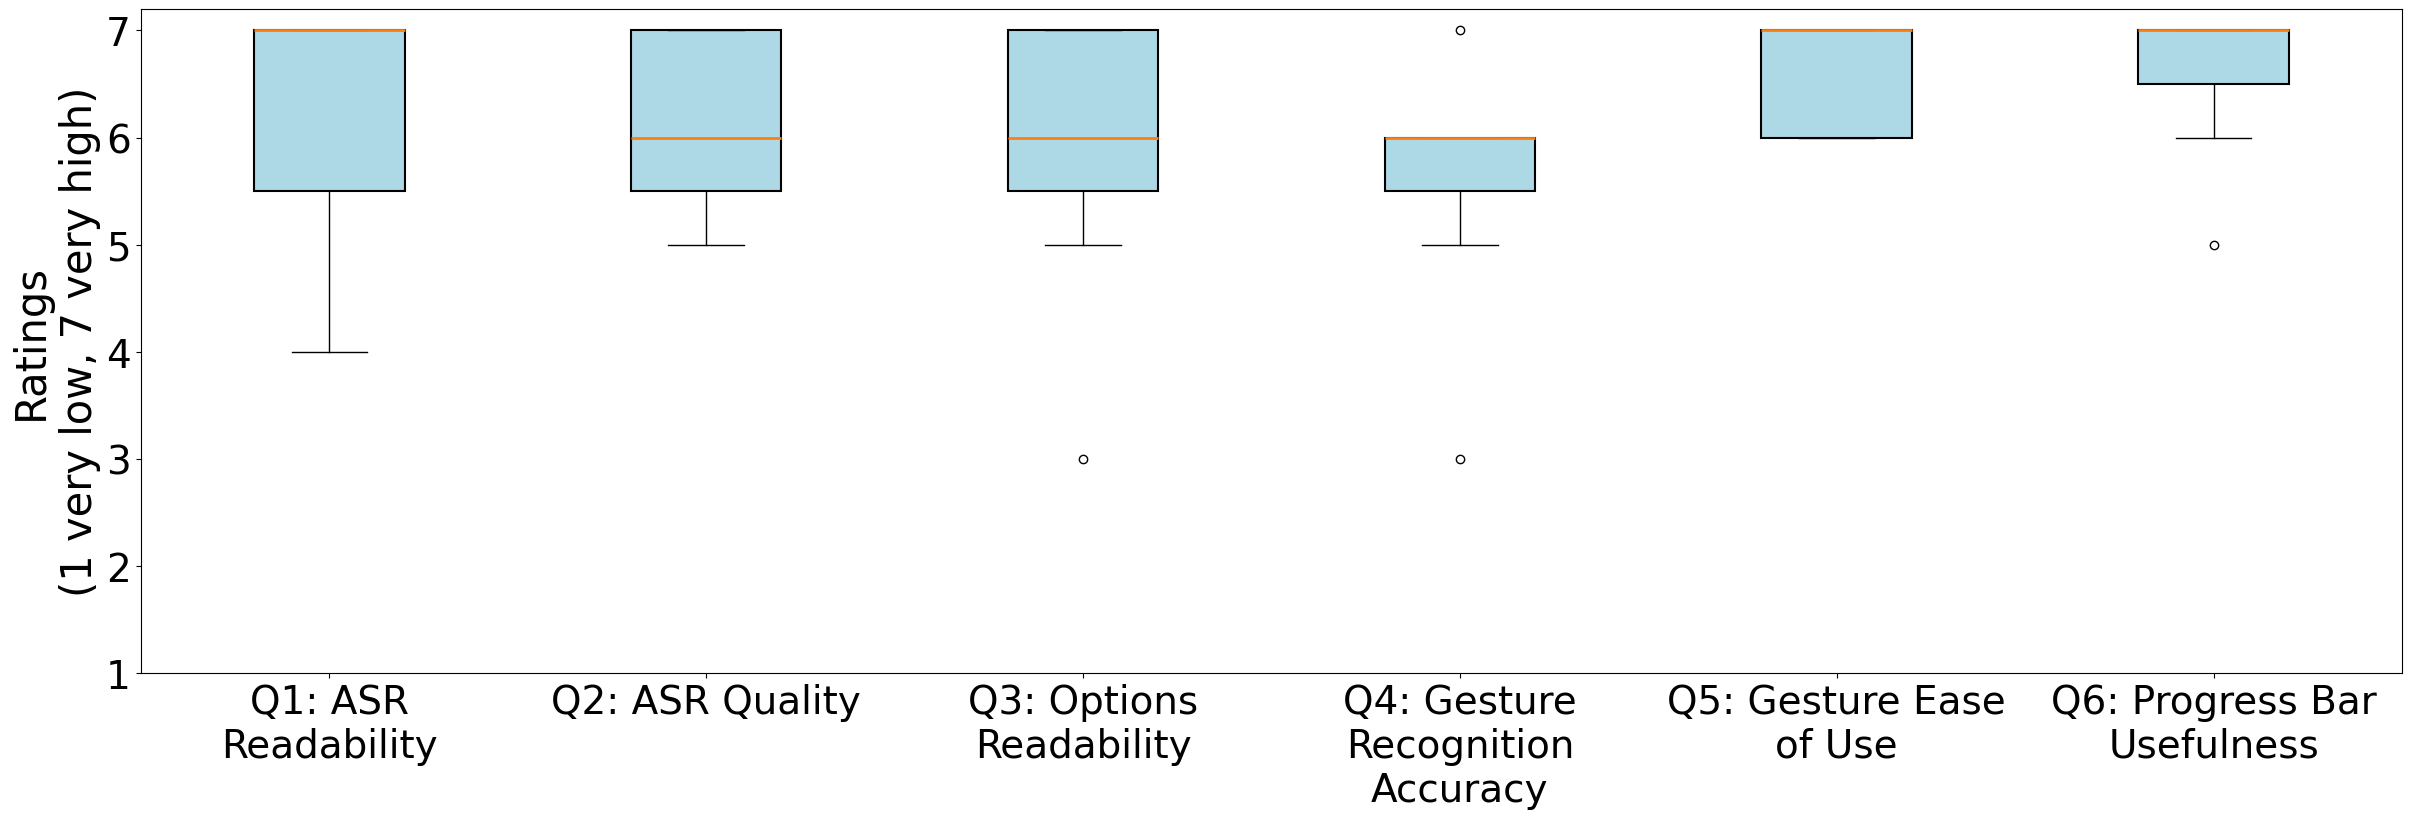

In [49]:
for question, data in ui_survey.items():
    q75, q25 = np.percentile(data, [75 ,25])
    iqr = q75 - q25
    print(question) 
    print("Median is ",np.median(data))
    print("Quartile 75%: ", q75)
    print("Quartile 25%: " ,q25)
    print("IQR", iqr)

plot_boxplot_single_dict(ui_survey, go_from_one=True, ylabel="Ratings\n(1 very low, 7 very high)", output_file = "ui_survey.png")